# Week 11: DBSCAN and Hierarchical Clustering
### Victor Vasquez Gil | Boston University | Integrated Capstone
DX799 — Module C | Week 11

### What I want to find out
In Week 10, I used K-means to group loans with similar financial profiles. This week, I want to see what changes when a method can leave some loans ungrouped or build groups through a series of merges. For my capstone, I am interested in whether these groups help me understand the borrowers and ask better questions about loan risk.

I use DBSCAN to look for dense groups and hierarchical agglomerative clustering (HAC) to compare single, complete, average, and Ward linkage. I want to know whether I can explain the groups and how much the results depend on the settings. Repayment outcomes come back into the analysis after those choices are fixed. A cluster number or a noise label does not tell me whether an individual borrower will repay.

I keep the six financial features and the local-data approach used in Week 10. This notebook runs on its own using an existing Lending Club file or a compatible local sample. The small examples explain the methods; the tables and figures later in the notebook show the loan results.
 

In [1]:
from pathlib import Path
import os, sys, json, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from IPython.display import display, HTML, Markdown, Image
from threadpoolctl import threadpool_limits
import sklearn
import scipy
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from scipy.spatial.distance import pdist
from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.exceptions import ConvergenceWarning

SEED = 42
SAMPLE_SIZE = 50_000
PARENT_SIZE = 10_000
ANALYSIS_SIZE = 2_500
CHUNK_SIZE = 25_000
EXPECTED_SOURCE_ROWS = 2_260_701
SILHOUETTE_SAMPLE = 800
MIN_SAMPLES_VALUES = [6, 12, 24]
EPS_QUANTILES = [.50, .65, .80, .90, .95]
HAC_K_VALUES = list(range(2, 7))
LINKAGES = ["single", "complete", "average", "ward"]
MIN_GROUP_SHARE = .01
MIN_DB_COVERAGE = .50
MAX_DB_GROUPS = 8
DATA_PATH = None
SAMPLE_PATH = None
DATASET_URL = "https://www.kaggle.com/datasets/wordsforthewise/lending-club"
OUTPUT_DIR = Path("week11_outputs")
CACHE_DIR = Path("capstone_cache")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Reader columns match the existing capstone sample format.
NUMERIC = ["loan_amnt", "annual_inc", "dti", "fico_range_low", "open_acc", "pub_rec",
           "revol_bal", "revol_util", "total_acc", "delinq_2yrs", "inq_last_6mths"]
CATEGORICAL = ["term", "home_ownership", "purpose", "emp_length"]
FEATURES = NUMERIC + CATEGORICAL
CLUSTER_FEATURES = ["loan_amnt", "annual_inc", "dti", "fico_range_low", "revol_util", "revol_bal"]
MONEY_POSITIONS = [0, 1, 5]
SHORT_NAMES = ["Loan amount", "Annual income", "DTI", "FICO", "Revolving utilization", "Revolving balance"]
TEAL, BLUE, ORANGE, GRAY = "#137C8B", "#315F91", "#B85C20", "#6B7280"
COLORS = plt.get_cmap("tab10").colors
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.titlesize": 12,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .20})
thread_limit = threadpool_limits(limits=1)

def show_table(frame, decimals=3):
    display(HTML(frame.to_html(index=False, border=0,
        float_format=lambda x: f"{x:,.{decimals}f}")))

def finish(fig, name):
    path = OUTPUT_DIR / f"{name}.png"
    fig.savefig(path, dpi=180, bbox_inches="tight", facecolor="white")
    display(Image(filename=str(path)))
    plt.close(fig)

def clean_number(series):
    return pd.to_numeric(series.astype("string").str.strip()
        .str.replace(",", "", regex=False).str.replace("%", "", regex=False),
        errors="coerce").astype(float).replace([np.inf, -np.inf], np.nan)

def log_money(values):
    result = np.asarray(values, dtype=float).copy()
    result[:, MONEY_POSITIONS] = np.log1p(result[:, MONEY_POSITIONS])
    return result

def make_prepare():
    return Pipeline([("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("log_money", FunctionTransformer(log_money, validate=False)),
        ("scale", StandardScaler())])

def point_types(model):
    kinds = np.where(model.labels_ == -1, "Noise", "Border").astype(object)
    kinds[model.core_sample_indices_] = "Core"
    return kinds

def safe_silhouette(values, labels):
    if not 2 <= len(np.unique(labels)) < len(labels):
        return np.nan
    return float(silhouette_score(values, labels, metric="euclidean"))

def partition_stats(values, labels, evaluation_positions):
    labels = np.asarray(labels)
    assigned = labels >= 0
    groups, counts = np.unique(labels[assigned], return_counts=True)
    evaluated = evaluation_positions[labels[evaluation_positions] >= 0]
    represented = len(np.unique(labels[evaluated]))
    return {"Clusters": len(groups), "Coverage": float(assigned.mean()),
        "Noise share": float((~assigned).mean()),
        "Smallest group": int(counts.min()) if len(counts) else 0,
        "Largest group": int(counts.max()) if len(counts) else 0,
        "Silhouette": safe_silhouette(values[evaluated], labels[evaluated]),
        "Evaluated loans": len(evaluated), "Evaluated clusters": represented}

def group_name(label):
    return "Noise" if label == -1 else f"Cluster {int(label)+1}"

def cut_height(tree, k):
    # There are n-k completed merges at the cut. Equal adjacent heights may
    # prevent a horizontal line from reproducing an exact-k merge-order cut.
    n = len(tree) + 1
    lower, upper = tree[n-k-1, 2], tree[n-k, 2]
    return float((lower+upper)/2) if upper > lower else None

print(f"Python {sys.version.split()[0]} | sklearn {sklearn.__version__} | SciPy {scipy.__version__}")
print("Dataset reference:", DATASET_URL)

Python 3.14.2 | sklearn 1.9.1 | SciPy 1.18.1
Dataset reference: https://www.kaggle.com/datasets/wordsforthewise/lending-club


## 2. What the two methods are doing

#### DBSCAN
DBSCAN groups points where there are enough nearby observations. I choose `eps`, the neighborhood radius, and `min_samples`, the minimum number of points inside that radius, including the point itself. These settings determine three types of points:
* **A core point:** Has at least `min_samples` points within its radius.
* **A border point:** Does not meet that count, but is within the radius of a core point.
* **A noise point:** Is neither core nor border and receives label `-1`.

##### How Clusters Form & Loan Expectations
* **Cluster connectivity:** Core points connect when I can move from one to another in steps no longer than `eps`, and their nearby border points are included in the group. This lets DBSCAN follow shapes that a compact cluster around a center might miss, and means the full cluster can extend much farther than one radius.
* **Border point limits:** A border point cannot connect two separate clusters by itself. If it is close to core points in two different clusters, its assignment can depend on which cluster is reached first.
* **Parameter sensitivity for loans:** A small radius or a larger minimum count leaves more observations as noise, whereas a large radius can merge groups that looked separate at a smaller radius. While I do not have to choose the number of clusters beforehand, I still have to define what counts as a dense neighborhood. A loan labeled noise is simply unusual under those choices; that does not establish that the record is wrong or the borrower is likely to charge off.

---

#### Hierarchical Agglomerative Clustering (HAC)
HAC starts with each loan in its own group and repeatedly merges two groups. The linkage rule determines which pair merges next:

| Linkage | How it compares groups | What I watch for |
| :--- | :--- | :--- |
| **Single** | Uses the closest pair of points across the two groups. | A chain of nearby points can connect otherwise different groups. |
| **Complete** | Uses the farthest pair across the groups. | An extreme point can strongly affect the distance. |
| **Average** | Uses the mean of all distances between pairs across the groups. | The result still depends on scaling and the distance metric. |
| **Ward** | Uses the increase in total within-group squared error. | It favors compact groups and requires Euclidean geometry. |

##### Ward's Merge Cost & Dendrograms
Ward's merge cost is the increase in the sum of squared errors, accounting for both group sizes:

$$\Delta\mathrm{SSE}(A,B) = \frac{n_A n_B}{n_A+n_B}\lVert\bar{x}_A-\bar{x}_B\rVert_2^2$$

* **Dendrograms & tree cuts:** A dendrogram shows the sequence of merges. The height of a join gives its linkage value (not a repayment probability), and a horizontal cut identifies the groups below that height.
* **Linkage sensitivity:** I can inspect the tree before choosing where to cut it. Different linkage rules can produce different trees from the same loans, so the rule is part of the result I need to explain.

---

#### Teaching Examples Before Using the Loans
* **Synthetic examples:** The next cell uses a made-up DBSCAN example to show core, border, and noise points, alongside the cookie groups `[4, 4.5]` and `[6, 7]` from the lesson to compare the four linkage calculations.
* **SciPy Ward height:** In SciPy, the Ward merge height is $\sqrt{2\Delta\mathrm{SSE}}$, rather than the raw increase in SSE. These examples help me read the loan plots correctly without treating the teaching values as loan data.

Point,x,y,Type,Group
1,-0.10,0.00,Core,Cluster 1
2,0.00,0.00,Core,Cluster 1
3,0.10,0.00,Core,Cluster 1
4,0.00,0.10,Core,Cluster 1
5,0.28,0.00,Border,Cluster 1
6,1.00,1.00,Core,Cluster 2
7,1.05,1.00,Core,Cluster 2
8,1.00,1.05,Core,Cluster 2
9,0.95,1.00,Core,Cluster 2
10,2.20,0.30,Noise,Noise


Merge,single,complete,average,ward
1,0.5000,0.5000,0.5000,0.5000
2,1.0000,1.0000,1.0000,1.0000
3,1.5000,3.0000,2.2500,3.1820
4,4.0000,7.0000,5.6250,7.1151


"Linkage quantity for [4, 4.5] and [6, 7]",Value
Single distance,1.5000
Complete distance,3.0000
Average distance,2.2500
Ward SSE increase,5.0625
SciPy Ward height,3.1820


Ward: SSE before = 0.6250; after = 5.6875; increase = 5.0625


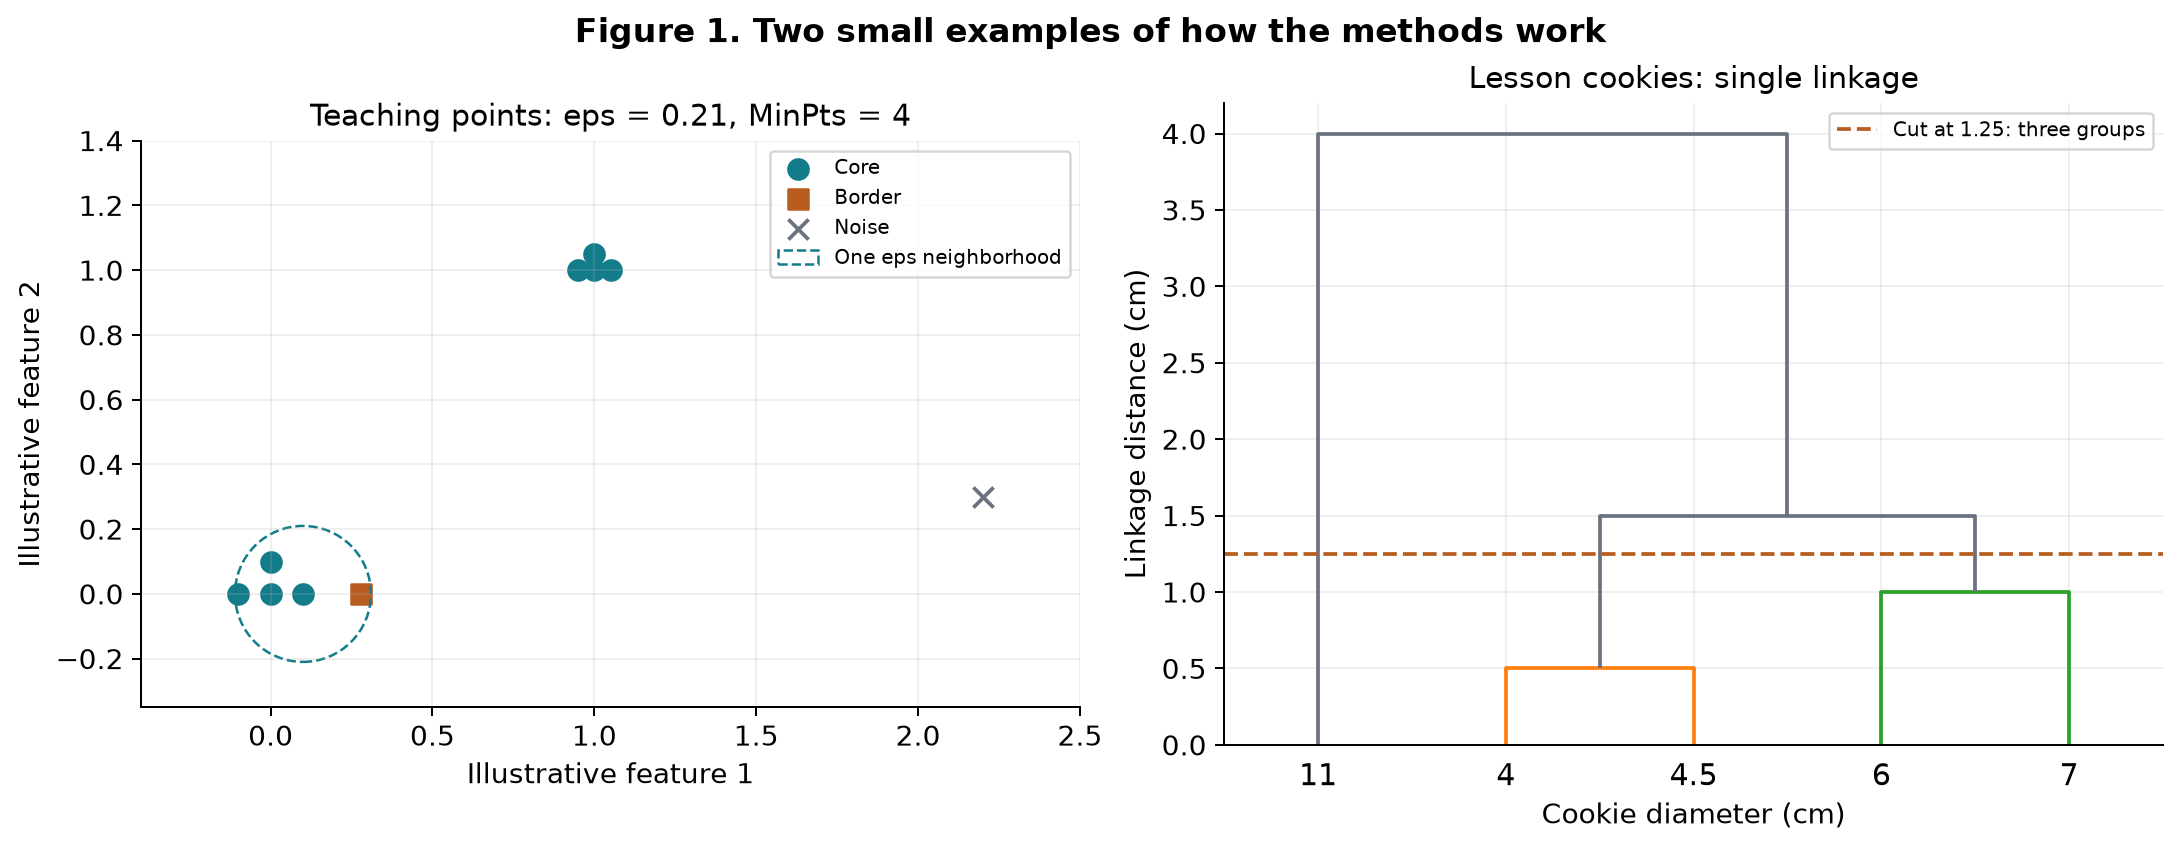

In [2]:
demo = np.array([[-.1, 0], [0, 0], [.1, 0], [0, .1], [.28, 0],
                 [1, 1], [1.05, 1], [1, 1.05], [.95, 1], [2.2, .3]])
demo_model = DBSCAN(eps=.21, min_samples=4, algorithm="ball_tree", n_jobs=1).fit(demo)
demo_types = point_types(demo_model)
show_table(pd.DataFrame({"Point": np.arange(1, len(demo)+1), "x": demo[:, 0], "y": demo[:, 1],
    "Type": demo_types, "Group": [group_name(c) for c in demo_model.labels_]}), 2)

cookies = np.array([4., 4.5, 6., 7., 11.])[:, None]
cookie_trees = {method: linkage(cookies, method=method, metric="euclidean") for method in LINKAGES}
cookie_merges = pd.DataFrame({"Merge": np.arange(1, 5),
    **{method: tree[:, 2] for method, tree in cookie_trees.items()}})
show_table(cookie_merges, 4)
A, B = cookies[:2], cookies[2:4]
before_sse = float(((A-A.mean(axis=0))**2).sum() + ((B-B.mean(axis=0))**2).sum())
merged = np.vstack([A, B])
after_sse = float(((merged-merged.mean(axis=0))**2).sum())
ward_increase = after_sse - before_sse
cross_distances = np.abs(A-B.T)
show_table(pd.DataFrame({"Linkage quantity for [4, 4.5] and [6, 7]":
    ["Single distance", "Complete distance", "Average distance", "Ward SSE increase", "SciPy Ward height"],
    "Value": [cross_distances.min(), cross_distances.max(), cross_distances.mean(),
              ward_increase, np.sqrt(2*ward_increase)]}), 4)
print(f"Ward: SSE before = {before_sse:.4f}; after = {after_sse:.4f}; increase = {ward_increase:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout="constrained")
for kind, marker, color in [("Core", "o", TEAL), ("Border", "s", ORANGE), ("Noise", "x", GRAY)]:
    mask = demo_types == kind
    axes[0].scatter(demo[mask, 0], demo[mask, 1], s=65, marker=marker, color=color, label=kind)
axes[0].add_patch(Circle(demo[2], .21, fill=False, color=TEAL, linestyle="--", label="One eps neighborhood"))
axes[0].set(title="Teaching points: eps = 0.21, MinPts = 4", xlabel="Illustrative feature 1",
            ylabel="Illustrative feature 2", xlim=(-.4, 2.5), ylim=(-.35, 1.4))
axes[0].legend(loc="upper right", fontsize=8)
axes[0].set_aspect("equal", adjustable="box")
dendrogram(cookie_trees["single"], labels=["4", "4.5", "6", "7", "11"],
           color_threshold=1.25, above_threshold_color=GRAY, ax=axes[1])
axes[1].axhline(1.25, color=ORANGE, ls="--", label="Cut at 1.25: three groups")
axes[1].set(title="Lesson cookies: single linkage", xlabel="Cookie diameter (cm)", ylabel="Linkage distance (cm)")
axes[1].legend(fontsize=8)
fig.suptitle("Figure 1. Two small examples of how the methods work", fontweight="bold")
finish(fig, "figure_1_teaching_examples")
cookie_merges.to_csv(OUTPUT_DIR / "lesson_cookie_merges.csv", index=False)

## 3. Keep the loan data consistent
I use the same accepted-loan source and resolved-outcome filter as Week 10: Fully Paid or Charged Off. The reader can reuse the existing 50,000 loan cache. From that sample, I recreate the 10,000 loan parent subset and randomly take 2,500 loans for this analysis. The smaller subset keeps the pairwise distance calculations manageable. It is not stratified by repayment outcome.

The features are loan amount, annual income, DTI, origination FICO, revolving utilization, and revolving balance. I keep payment information, recoveries, loan grade, interest rate, identifiers, and loan_status out of the clustering. I check duplicate IDs and apply the same fixed rules for invalid numeric values as Week 10.

I impute missing values with this analysis subset's medians, log the three dollar features with log1p, and standardize all six features. This reduces scale differences without removing every outlier. The transformations are reestimated on the smaller subset, so this is consistent preprocessing, not the exact fitted Week 10 scaler.

This is an exploratory analysis of one sample. DBSCAN and the HAC implementation here do not provide a native predict method for new loans. I therefore check sensitivity by refitting on smaller samples. 

In [3]:
def check_sample(sample, info):
    expected = {"cohort": "outcome", "seed": SEED, "sample_size": SAMPLE_SIZE,
                "chunk_size": CHUNK_SIZE, "algorithm": "priority-v1",
                "rows_scanned": EXPECTED_SOURCE_ROWS, "sample_rows": SAMPLE_SIZE}
    wrong = {key: (info.get(key), value) for key, value in expected.items()
             if info.get(key) != value}
    if wrong:
        raise ValueError(f"This cache does not match the configured sampling settings: {wrong}")
    missing = sorted(set(FEATURES + ["loan_status", "source_row"]) - set(sample.columns))
    if missing:
        raise ValueError(f"Sample columns missing: {missing}")
    if len(sample) != SAMPLE_SIZE:
        raise ValueError(f"Expected {SAMPLE_SIZE:,} sampled loans; found {len(sample):,}.")
    sample = sample.copy()
    sample["source_row"] = pd.to_numeric(sample["source_row"], errors="raise").astype("int64")
    if (sample.source_row.duplicated().any() or sample.source_row.lt(0).any()
            or sample.source_row.ge(EXPECTED_SOURCE_ROWS).any()):
        raise ValueError("Invalid or repeated source-row numbers in the sample.")
    sample["loan_status"] = sample.loan_status.astype("string").str.strip()
    if not sample.loan_status.isin(["Fully Paid", "Charged Off"]).all():
        raise ValueError("The sample must contain only Fully Paid and Charged Off loans.")
    return sample.reset_index(drop=True)

def read_sample_cache(path):
    path = Path(path).expanduser()
    if not str(path).endswith(".csv.gz"):
        raise ValueError("SAMPLE_PATH must name an existing outcome_*.csv.gz sample.")
    info_path = Path(str(path)[:-7] + ".json")
    if not path.is_file() or not info_path.is_file():
        raise FileNotFoundError(f"The sample and its matching JSON file are required: {path}")
    info = json.loads(info_path.read_text())
    sample = check_sample(pd.read_csv(path, dtype="string"), info)
    print("Using existing sample:", path)
    return sample, info, str(path.resolve())

def accepted_file(folder):
    folder = Path(folder).expanduser()
    if folder.is_file():
        return folder
    if not folder.is_dir():
        return None
    # Prefer the compressed copy when both representations are already present.
    for name in ["accepted_2007_to_2018Q4.csv.gz", "accepted_2007_to_2018Q4.csv"]:
        matches = sorted(p for p in folder.rglob(name) if p.is_file())
        if matches:
            return matches[0]
    return None

def locate_source(configured):
    configured = configured or os.environ.get("LENDING_CLUB_CSV")
    if configured:
        if str(configured).startswith(("http://", "https://")):
            raise ValueError("DATA_PATH must be a local file. The Kaggle URL is a citation.")
        found = accepted_file(configured)
        if found:
            return found
        raise FileNotFoundError(f"No accepted-loans file at DATA_PATH: {configured}")
    roots = [
        Path.home()/".cache/kagglehub/datasets/wordsforthewise/lending-club/versions/3",
        Path("/home/codespace/.cache/kagglehub/datasets/wordsforthewise/lending-club/versions/3"),
        Path.cwd()/"data", Path.cwd(), Path("/kaggle/input"), Path("/content")
    ]
    for root in roots:
        found = accepted_file(root)
        if found:
            return found
    raise FileNotFoundError(
        "No existing accepted-loans file or compatible local sample cache was found. "
        "Set DATA_PATH to your local accepted_2007_to_2018Q4.csv.gz (or .csv), "
        "or set SAMPLE_PATH to your existing outcome_*.csv.gz with its JSON file. "
        "This notebook does not download data."
    )

def sample_source(path):
    header = pd.read_csv(path, nrows=0)
    missing = sorted(set(FEATURES + ["loan_status"]) - set(header.columns))
    if missing:
        raise ValueError(f"Required accepted-loans columns missing: {missing}")
    requested = list(dict.fromkeys(FEATURES + ["int_rate", "loan_status", "id", "member_id", "issue_d"]))
    requested = [col for col in requested if col in header.columns]
    fingerprint = {"resolved_path": str(path.resolve()), "bytes": path.stat().st_size,
        "mtime_ns": path.stat().st_mtime_ns, "cohort": "outcome", "seed": SEED,
        "sample_size": SAMPLE_SIZE, "chunk_size": CHUNK_SIZE, "algorithm": "priority-v1"}
    rng = np.random.default_rng(SEED)
    sample, scanned, eligible = None, 0, 0
    status_counts = pd.Series(dtype="int64")
    for batch, chunk in enumerate(pd.read_csv(path, usecols=requested, dtype="string",
                    chunksize=CHUNK_SIZE, low_memory=False), 1):
        chunk["source_row"] = np.arange(scanned, scanned + len(chunk))
        scanned += len(chunk)
        chunk["loan_status"] = chunk.loan_status.str.strip()
        status_counts = status_counts.add(
            chunk.loan_status.fillna("Missing").value_counts(), fill_value=0)
        chunk = chunk.loc[chunk.loan_status.isin(["Fully Paid", "Charged Off"])].copy()
        eligible += len(chunk)
        if len(chunk):
            chunk["_priority"] = rng.random(len(chunk))
            sample = chunk if sample is None else pd.concat([sample, chunk], ignore_index=True)
            sample = sample.nsmallest(SAMPLE_SIZE, "_priority")
        if batch % 20 == 0:
            print(f"Scanned {scanned:,} rows | eligible loans: {eligible:,}", flush=True)
    if scanned != EXPECTED_SOURCE_ROWS:
        raise ValueError(f"Read {scanned:,} rows; the accepted-loans version-3 file has "
                         f"{EXPECTED_SOURCE_ROWS:,}. Check that the source file is complete.")
    if sample is None:
        raise ValueError("No eligible loans were found.")
    sample = sample.drop(columns="_priority").reset_index(drop=True)
    info = {**fingerprint, "rows_scanned": scanned, "eligible_rows": eligible,
            "sample_rows": len(sample)}
    sample = check_sample(sample, info)
    key = hashlib.sha256(json.dumps(fingerprint, sort_keys=True).encode()).hexdigest()[:16]
    cache_file = CACHE_DIR / f"outcome_{key}.csv.gz"
    sample.to_csv(cache_file, index=False, compression="gzip")
    (CACHE_DIR / f"outcome_{key}.json").write_text(json.dumps(info, indent=2))
    status_counts.astype(int).to_csv(OUTPUT_DIR / "source_status_counts.csv")
    return sample, info, str(path.resolve())

def load_loans():
    if SAMPLE_PATH is not None and DATA_PATH is not None:
        raise ValueError("Set only SAMPLE_PATH or DATA_PATH, so the intended source is clear.")
    if SAMPLE_PATH is not None:
        return read_sample_cache(SAMPLE_PATH)
    if DATA_PATH is None and not os.environ.get("LENDING_CLUB_CSV"):
        for candidate in sorted(CACHE_DIR.glob("outcome_*.csv.gz")):
            try:
                return read_sample_cache(candidate)
            except (ValueError, FileNotFoundError, KeyError) as error:
                print(f"Skipping incompatible cache {candidate.name}: {error}")
    source = locate_source(DATA_PATH)
    print("Using existing dataset:", source)
    # Reuse a saved sample from this exact source if available.
    for candidate in sorted(CACHE_DIR.glob("outcome_*.csv.gz")):
        info_path = Path(str(candidate)[:-7] + ".json")
        if info_path.is_file():
            info = json.loads(info_path.read_text())
            if (info.get("resolved_path") == str(source.resolve())
                and info.get("bytes") == source.stat().st_size
                and info.get("mtime_ns") == source.stat().st_mtime_ns):
                return read_sample_cache(candidate)
    return sample_source(source)

In [4]:
loans, source_info, source_used = load_loans()
if not ANALYSIS_SIZE <= PARENT_SIZE <= len(loans):
    raise ValueError("Require ANALYSIS_SIZE <= PARENT_SIZE <= the number of cached loans.")
parent = loans.sample(n=PARENT_SIZE, random_state=SEED)
study = parent.sample(n=ANALYSIS_SIZE, random_state=SEED).copy()
for key in ["id", "member_id"]:
    if key in study:
        ids = study[key].astype("string").str.strip().replace("", pd.NA).dropna()
        if ids.duplicated().any():
            raise ValueError(f"Repeated {key}: resolve repeated loans or borrowers before interpreting clusters.")
if "member_id" not in study or study.member_id.astype("string").str.strip().replace("", pd.NA).isna().all():
    print("No usable borrower ID: repeated borrowers cannot be fully checked.")

X = study[CLUSTER_FEATURES].apply(clean_number)
invalid = pd.DataFrame(False, index=X.index, columns=X.columns)
for col in ["loan_amnt", "annual_inc", "dti", "revol_util", "revol_bal"]:
    invalid[col] = X[col].lt(0)
invalid["loan_amnt"] = X.loan_amnt.le(0)
invalid["fico_range_low"] = X.fico_range_low.notna() & ~X.fico_range_low.between(300, 850)
X = X.mask(invalid)
if X.isna().all().any():
    raise ValueError("At least one clustering feature is entirely missing.")
assert "loan_status" not in X.columns
prepare = make_prepare()
Z = prepare.fit_transform(X)
if not np.isfinite(Z).all() or np.unique(Z, axis=0).shape[0] < max(HAC_K_VALUES):
    raise ValueError("Need finite values and enough distinct financial profiles.")
eval_positions = np.sort(np.random.default_rng(SEED).choice(len(Z), min(SILHOUETTE_SAMPLE, len(Z)), replace=False))
min_group_size = max(2, int(np.ceil(MIN_GROUP_SHARE * len(Z))))
show_table(pd.DataFrame({"Stage": ["Resolved-loan sample", "Parent subset", "Week 11 analysis", "Silhouette evaluation pool"],
    "Loans": [len(loans), len(parent), len(study), len(eval_positions)]}), 0)
study[["source_row"]].to_csv(OUTPUT_DIR / "analysis_rows.csv", index=False)
run_info = {"data_url": DATASET_URL, "source_used": source_used, "source_metadata": source_info,
    "seed": SEED, "analysis_rows": len(study), "features": CLUSTER_FEATURES,
    "source_rows_sha256": hashlib.sha256(study.source_row.to_numpy(dtype="int64").tobytes()).hexdigest(),
    "python": sys.version.split()[0], "sklearn": sklearn.__version__, "scipy": scipy.__version__,
    "pandas": pd.__version__, "preprocessing": "median imputation, log1p dollar features, StandardScaler",
    "evaluation": "exploratory sample; no held-out predictive test"}
(OUTPUT_DIR / "run_provenance.json").write_text(json.dumps(run_info, indent=2))
print("Loan outcomes are set aside until the clustering choices are fixed.")

Using existing sample: capstone_cache/outcome_6052281cfec00759.csv.gz
No usable borrower ID: repeated borrowers cannot be fully checked.


Stage,Loans
Resolved-loan sample,50000
Parent subset,10000
Week 11 analysis,2500
Silhouette evaluation pool,800


Loan outcomes are set aside until the clustering choices are fixed.


## 4. Check the features and neighborhood distances
I start with missing values, ranges, and the largest standardized values. The table shows whether large observations remain after the log and scaling steps. Utilization above 100% is retained because it can occur.

The left panel of Figure 2 shows how much each feature contributes to squared distance across the same random pairs of loans, before and after preprocessing. That is a check on distance, not feature importance.

The right panel sorts each loan's distance to its min_samples-th nearest point, counting itself. I use these curves to describe the density scale and set a small range of candidate radii. A bend can be useful, but I do not assume that every curve has a clear one. The exact radius values are listed in the DBSCAN results.

Feature,min,median,max,Missing (%),Invalid values marked missing,Largest |z| after preprocessing
loan_amnt,"1,000.00","12,000.00","40,000.00",0.00,0,3.50
annual_inc,"5,700.00","65,000.00","4,266,080.00",0.00,0,7.71
dti,0.00,18.05,460.21,0.00,0,35.44
fico_range_low,660.00,690.00,845.00,0.00,0,4.65
revol_util,0.00,52.00,101.90,0.12,0,2.11
revol_bal,0.00,"11,094.50","391,654.00",0.00,0,7.05


Feature 1,Feature 2,Correlation
fico_range_low,revol_util,-0.488
revol_util,revol_bal,0.476
loan_amnt,annual_inc,0.459
loan_amnt,revol_bal,0.360
annual_inc,revol_bal,0.309


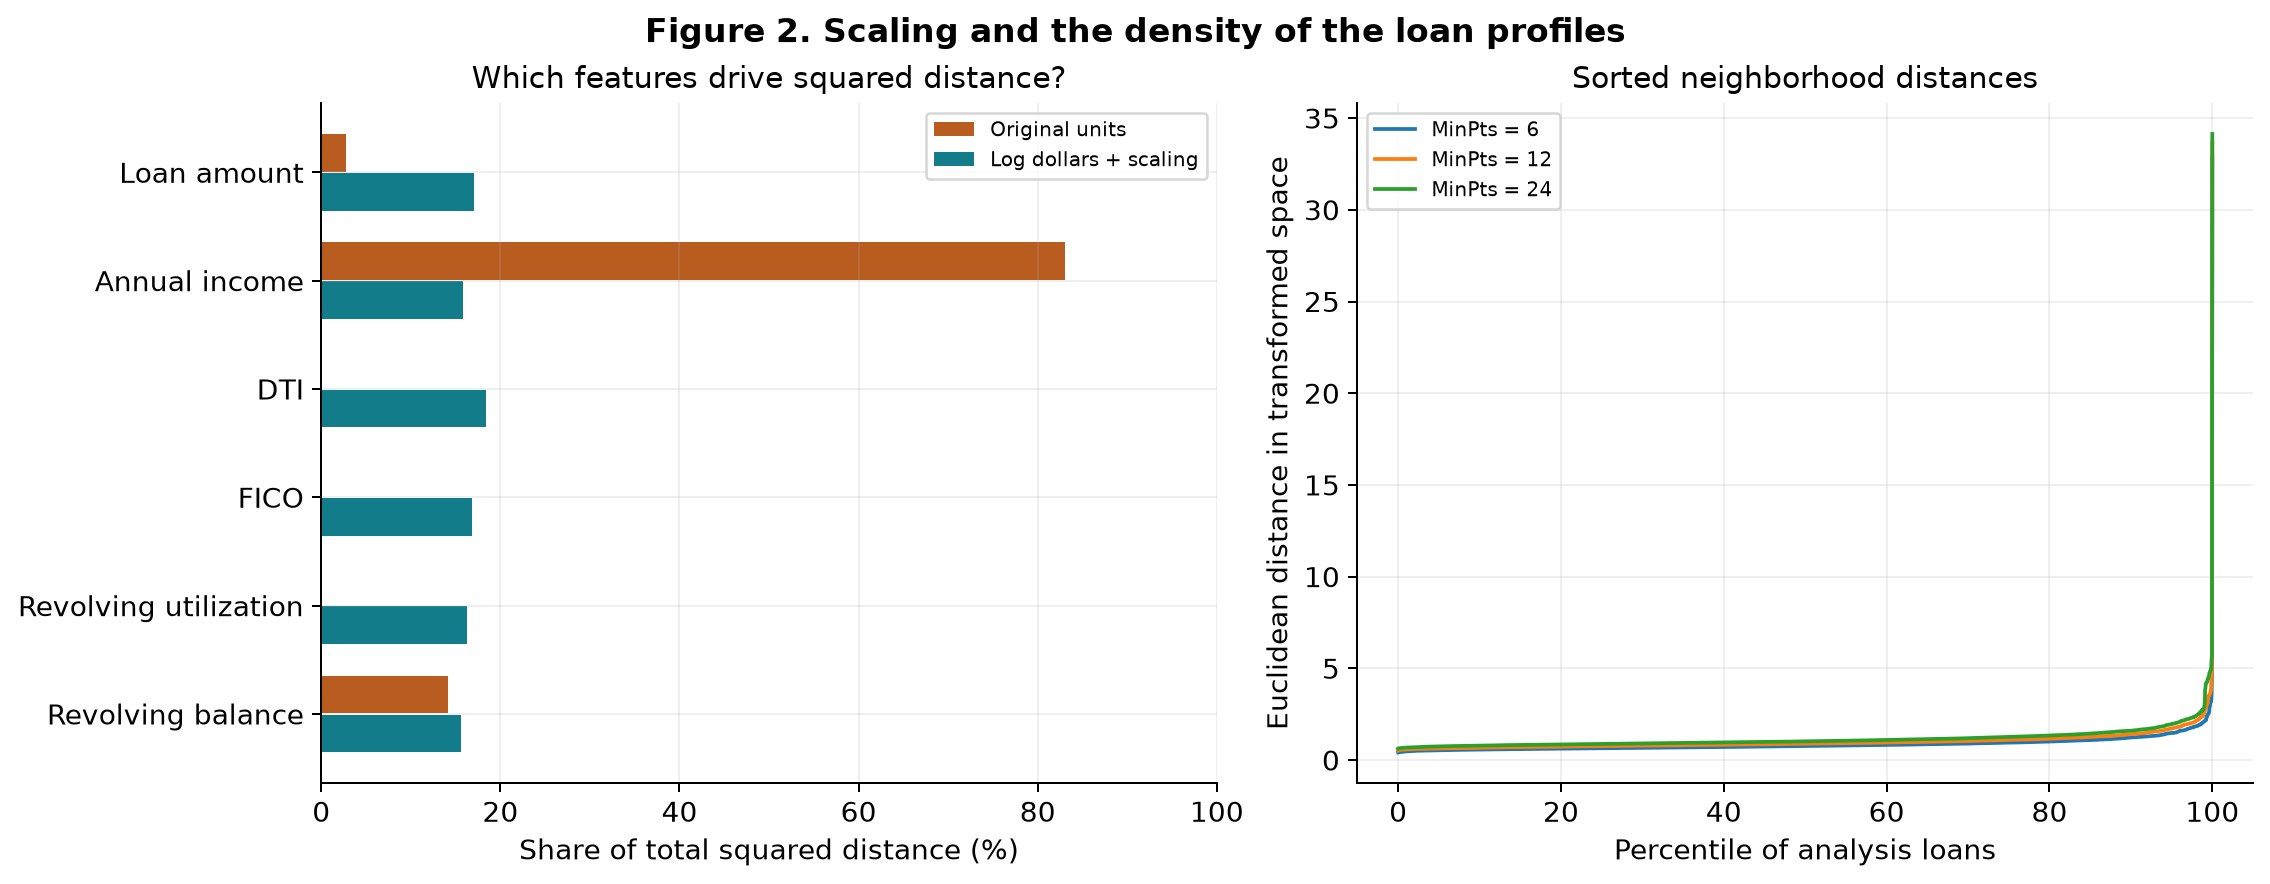

**What I see:** `annual_inc` accounts for 83.0% of squared distance across these random pairs in the original units. I use the transformed features for both clustering methods. Related features can still give some financial information extra weight after scaling.

In [5]:
range_table = X.agg(["min", "median", "max"]).T.rename_axis("Feature").reset_index()
range_table["Missing (%)"] = X.isna().mean().to_numpy()*100
range_table["Invalid values marked missing"] = invalid.sum().to_numpy()
range_table["Largest |z| after preprocessing"] = np.abs(Z).max(axis=0)
show_table(range_table, 2)
range_table.to_csv(OUTPUT_DIR / "ranges_missingness_outliers.csv", index=False)
corr = pd.DataFrame(Z, columns=CLUSTER_FEATURES).corr()
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().rename("Correlation").reset_index()
pairs.columns = ["Feature 1", "Feature 2", "Correlation"]
pairs = pairs.iloc[np.argsort(-np.abs(pairs.Correlation.to_numpy()))]
show_table(pairs.head(5))
pairs.to_csv(OUTPUT_DIR / "transformed_correlations.csv", index=False)

raw = prepare.named_steps["impute"].transform(X)
rng = np.random.default_rng(SEED)
left = rng.integers(0, len(Z), 5_000)
right = (left+rng.integers(1, len(Z), 5_000)) % len(Z)
shares = {}
for name, values in [("Original units", raw), ("Log dollars + scaling", Z)]:
    squared = ((values[left]-values[right])**2).sum(axis=0)
    shares[name] = squared/squared.sum()
distance_table = pd.DataFrame({"Feature": CLUSTER_FEATURES, **shares})
distance_table.to_csv(OUTPUT_DIR / "distance_contributions.csv", index=False)
neighbor_distances = {}
for m in MIN_SAMPLES_VALUES:
    nn = NearestNeighbors(n_neighbors=m, metric="euclidean", algorithm="ball_tree", n_jobs=1).fit(Z)
    # Passing Z explicitly includes each query point itself among its neighbors.
    neighbor_distances[m] = nn.kneighbors(Z, return_distance=True)[0][:, -1]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), layout="constrained")
positions = np.arange(len(CLUSTER_FEATURES))
axes[0].barh(positions-.18, shares["Original units"]*100, height=.35, label="Original units", color=ORANGE)
axes[0].barh(positions+.18, shares["Log dollars + scaling"]*100, height=.35, label="Log dollars + scaling", color=TEAL)
axes[0].set_yticks(positions, SHORT_NAMES)
axes[0].invert_yaxis()
axes[0].set(title="Which features drive squared distance?", xlabel="Share of total squared distance (%)", xlim=(0, 100))
axes[0].legend(fontsize=8)
for i, m in enumerate(MIN_SAMPLES_VALUES):
    axes[1].plot(np.linspace(0, 100, len(Z)), np.sort(neighbor_distances[m]),
                 color=COLORS[i], label=f"MinPts = {m}")
axes[1].set(title="Sorted neighborhood distances", xlabel="Percentile of analysis loans", ylabel="Euclidean distance in transformed space")
axes[1].legend(fontsize=8)
fig.suptitle("Figure 2. Scaling and the density of the loan profiles", fontweight="bold")
finish(fig, "figure_2_scaling_neighbors")
dominant = distance_table.loc[distance_table["Original units"].idxmax()]
display(Markdown(f"**What I see:** `{dominant.Feature}` accounts for {dominant['Original units']:.1%} of squared distance "
    "across these random pairs in the original units. I use the transformed features for both clustering methods. "
    "Related features can still give some financial information extra weight after scaling."))

## 5. Try DBSCAN and check what it leaves out
I compare min_samples values of 6, 12, and 24. For each value, the candidate eps values come from the 50th, 65th, 80th, 90th, and 95th percentiles of its neighborhood distance curve. These percentiles give me a limited search range; they are not guaranteed to be the best radii. Because each curve is different, the same percentile can produce different radii for different minimum counts.

I report the number of clusters, core/border/noise counts, group sizes, coverage, and silhouette. Noise is excluded from silhouette. Treating all noise points as one real cluster would misrepresent the result. I use the same random evaluation pool throughout, then exclude its noise points for each setting. The evaluated loans can therefore differ between DBSCAN settings, and I report their number.

To keep the profiles manageable, I screen for 2-8 clusters, at least 50% coverage, and at least 1% of the analysis sample in every cluster. I also require every cluster to appear in the evaluation pool. These are choices for this exercise, not general DBSCAN rules. Among the passing settings, I take the highest silhouette, then higher coverage to break a tie.

If nothing passes, I keep MinPts = 12 and the 80th-percentile radius as a reference run and explicitly report that the search did not find a grouping that met the screens. One dense group plus noise can still be informative; I will not describe it as several well-separated borrower groups.

MinPts,Radius percentile,eps,Clusters,Coverage,Noise share,Smallest group,Largest group,Silhouette,Evaluated loans,Evaluated clusters,Core,Border,Noise,Passes screens
6,0.500,0.770,3,0.677,0.323,4,1682,0.092,533,3,1250,442,808,False
6,0.650,0.864,3,0.798,0.202,5,1984,0.153,640,3,1625,369,506,False
6,0.800,1.011,2,0.895,0.105,3,2235,0.186,719,2,2000,238,262,False
6,0.900,1.232,2,0.952,0.048,6,2374,0.293,761,2,2250,130,120,False
6,0.950,1.480,1,0.974,0.026,2435,2435,NaN,778,1,2375,60,65,False
12,0.500,0.894,1,0.739,0.261,1847,1847,NaN,583,1,1250,597,653,False
12,0.650,0.994,1,0.840,0.160,2100,2100,NaN,676,1,1625,475,400,False
12,0.800,1.166,1,0.913,0.087,2283,2283,NaN,731,1,2000,283,217,False
12,0.900,1.414,1,0.958,0.042,2395,2395,NaN,767,1,2250,145,105,False
12,0.950,1.721,1,0.980,0.020,2450,2450,NaN,785,1,2375,75,50,False


No setting passed all screens. This is the prespecified reference run, not a winning model.
DBSCAN shown below: eps = 1.1662, MinPts = 12


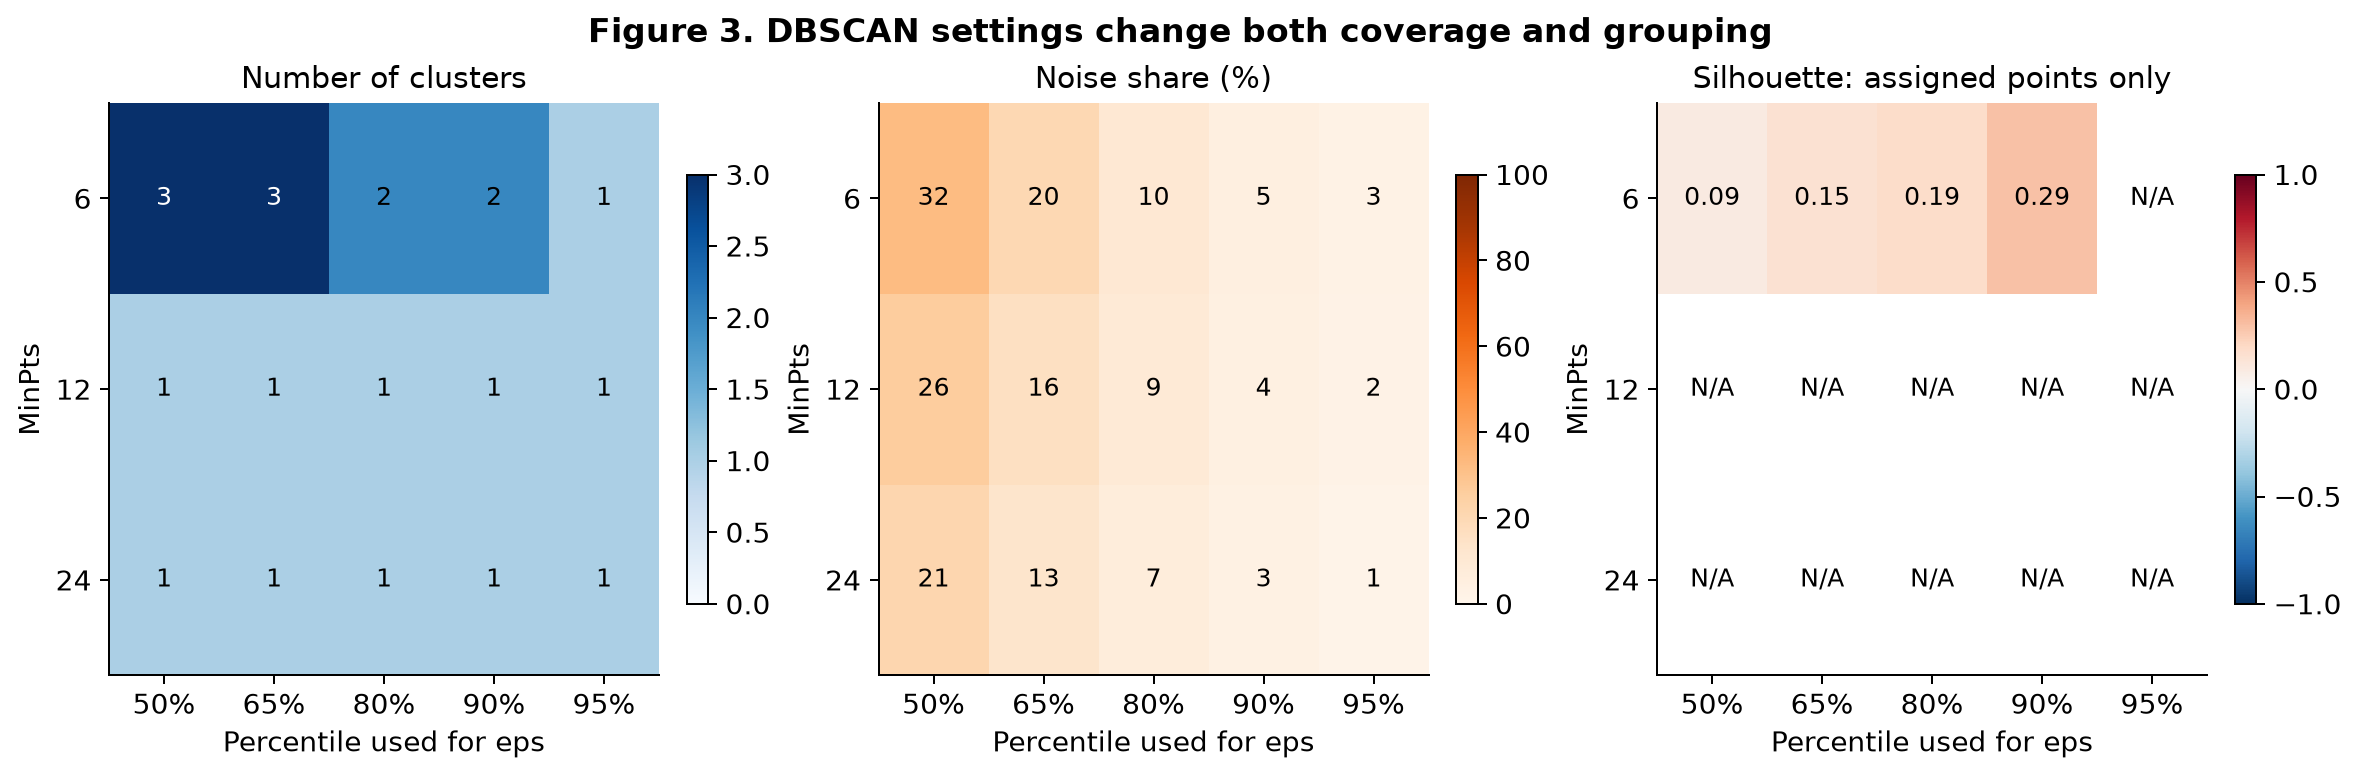

In [9]:
db_rows, db_runs = [], {}
for m in MIN_SAMPLES_VALUES:
    for quantile in EPS_QUANTILES:
        eps = max(float(np.quantile(neighbor_distances[m], quantile)), 1e-8)
        model = DBSCAN(eps=eps, min_samples=m, metric="euclidean", algorithm="ball_tree", n_jobs=1).fit(Z)
        labels, kinds = model.labels_.copy(), point_types(model)
        stats = partition_stats(Z, labels, eval_positions)
        eligible = (2 <= stats["Clusters"] <= MAX_DB_GROUPS
            and stats["Coverage"] >= MIN_DB_COVERAGE
            and stats["Smallest group"] >= min_group_size
            and stats["Evaluated clusters"] == stats["Clusters"]
            and np.isfinite(stats["Silhouette"]))
        run_id = len(db_rows)
        db_runs[run_id] = {"labels": labels, "types": kinds}
        db_rows.append({"Run": run_id, "MinPts": m, "Radius percentile": quantile,
            "eps": eps, **stats, "Core": int((kinds == "Core").sum()),
            "Border": int((kinds == "Border").sum()), "Noise": int((kinds == "Noise").sum()),
            "Passes screens": bool(eligible)})
db_results = pd.DataFrame(db_rows)
db_candidates = db_results.loc[db_results["Passes screens"]]
db_selected_by_score = not db_candidates.empty
if db_selected_by_score:
    db_choice = db_candidates.sort_values(["Silhouette", "Coverage", "MinPts", "eps"],
        ascending=[False, False, True, True]).iloc[0]
    db_selection_note = "Selected from the settings that passed the stated screens."
else:
    db_choice = db_results.loc[db_results.MinPts.eq(12) & np.isclose(db_results["Radius percentile"], .80)].iloc[0]
    db_selection_note = "No setting passed all screens. This is the prespecified reference run, not a winning model."
db_labels = db_runs[int(db_choice.Run)]["labels"]
db_types = db_runs[int(db_choice.Run)]["types"]
db_eps, db_minpts = float(db_choice.eps), int(db_choice.MinPts)
show_table(db_results.drop(columns="Run"), 3)
print(db_selection_note)
print(f"DBSCAN shown below: eps = {db_eps:.4f}, MinPts = {db_minpts}")
db_results.to_csv(OUTPUT_DIR / "dbscan_search.csv", index=False)
pd.DataFrame({"Type": ["Core", "Border", "Noise"],
              "Loans": [(db_types == kind).sum() for kind in ["Core", "Border", "Noise"]]}).to_csv(
                  OUTPUT_DIR / "dbscan_point_types.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), layout="constrained")
for ax, column, title, cmap, vmin, vmax in [
    (axes[0], "Clusters", "Number of clusters", "Blues", 0, None),
    (axes[1], "Noise share", "Noise share (%)", "Oranges", 0, 100),
    (axes[2], "Silhouette", "Silhouette: assigned points only", "RdBu_r", -1, 1)]:
    grid = db_results.pivot(index="MinPts", columns="Radius percentile", values=column).reindex(
        index=MIN_SAMPLES_VALUES, columns=EPS_QUANTILES).to_numpy(dtype=float)
    if column == "Noise share":
        grid = grid * 100
    im = ax.imshow(np.ma.masked_invalid(grid), cmap=cmap, aspect="auto", vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(EPS_QUANTILES)), [f"{q:.0%}" for q in EPS_QUANTILES])
    ax.set_yticks(range(len(MIN_SAMPLES_VALUES)), MIN_SAMPLES_VALUES)
    ax.set(title=title, xlabel="Percentile used for eps", ylabel="MinPts")
    ax.grid(False)
    for row in range(grid.shape[0]):
        for col in range(grid.shape[1]):
            value = grid[row, col]
            label = "N/A" if not np.isfinite(value) else (f"{value:.2f}" if column == "Silhouette" else f"{value:.0f}")
            color = "white" if np.isfinite(value) and im.norm(value) > .7 else "black"
            ax.text(col, row, label, ha="center", va="center", color=color, fontsize=10)
    fig.colorbar(im, ax=ax, shrink=.75)
fig.suptitle("Figure 3. DBSCAN settings change both coverage and grouping", fontweight="bold")
finish(fig, "figure_3_dbscan_search")

## 6. Compare HAC linkage methods
I build one hierarchy for each linkage method using the same 2,500 transformed loans and Euclidean distances. Ward needs Euclidean geometry. Single, complete, and average can use other distances, but keeping one distance here helps me isolate the effect of the linkage rule.

I cut each hierarchy at 2-6 groups and use the same evaluation pool for silhouette. I also show the smallest group size. A high score from one large group and a few isolated loans may be less useful for describing borrower profiles.

My screen again requires each group to contain at least 1% of the analysis sample and to appear in the evaluation pool. I select the highest silhouette among passing cuts, preferring fewer groups for an exact tie. If no cut passes, Ward with three groups remains a clearly labeled reference. These scores are used for selection on this sample, so they are not an independent estimate of future performance.

Linkage,k,Silhouette,Smallest group,Largest group,Evaluated clusters,Passes screens
single,2,NaN,1,2499,1,False
single,3,NaN,1,2498,1,False
single,4,0.605,1,2496,2,False
single,5,0.609,1,2479,3,False
single,6,0.609,1,2479,3,False
complete,2,NaN,1,2499,1,False
complete,3,0.153,1,1804,2,False
complete,4,0.174,1,1643,3,False
complete,5,0.165,1,1643,4,False
complete,6,0.165,1,1643,4,False


HAC shown below: ward linkage, k = 2
Selected from passing cuts.


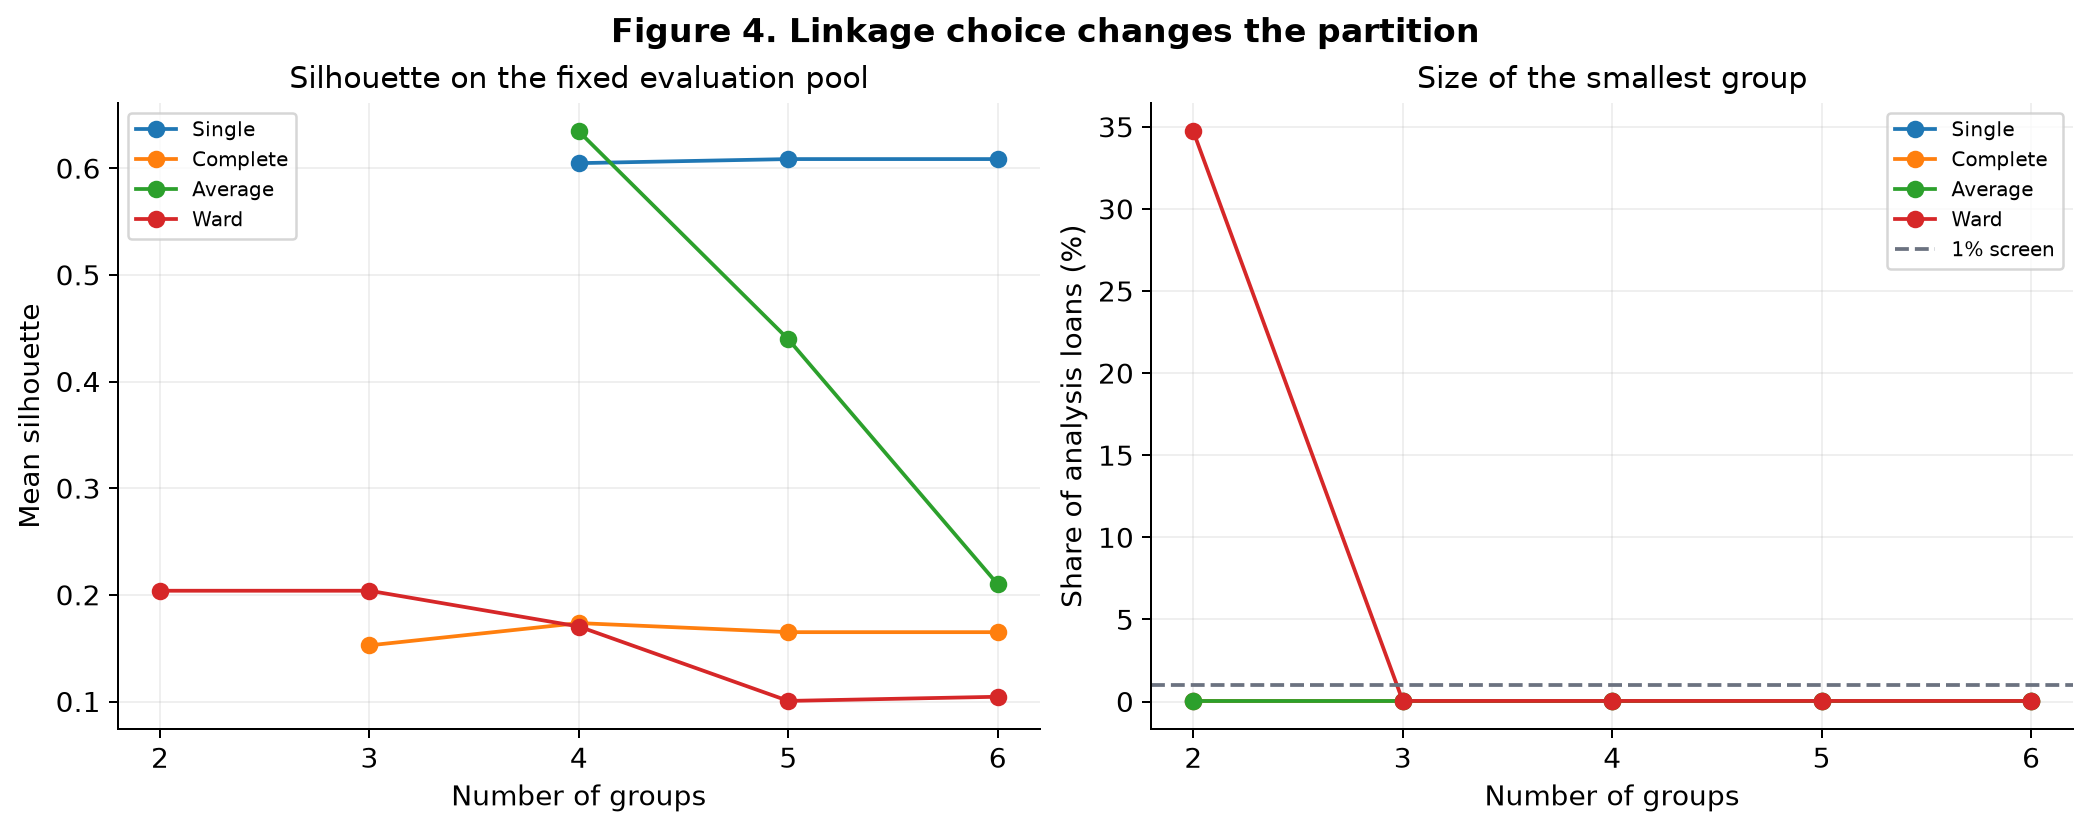

393

In [10]:
pair_distances = pdist(Z, metric="euclidean")
trees, hac_labels_by_setting, hac_rows = {}, {}, []
for method in LINKAGES:
    trees[method] = linkage(pair_distances, method=method)
    cuts = cut_tree(trees[method], n_clusters=HAC_K_VALUES)
    for column, k in enumerate(HAC_K_VALUES):
        labels = cuts[:, column]
        hac_labels_by_setting[(method, k)] = labels
        stats = partition_stats(Z, labels, eval_positions)
        eligible = (stats["Smallest group"] >= min_group_size
            and stats["Evaluated clusters"] == k and np.isfinite(stats["Silhouette"]))
        hac_rows.append({"Linkage": method, "k": k, **stats, "Passes screens": bool(eligible)})
hac_results = pd.DataFrame(hac_rows)
hac_candidates = hac_results.loc[hac_results["Passes screens"]]
hac_selected_by_score = not hac_candidates.empty
if hac_selected_by_score:
    hac_choice = hac_candidates.sort_values(["Silhouette", "k", "Linkage"], ascending=[False, True, True]).iloc[0]
else:
    hac_choice = hac_results.loc[hac_results.Linkage.eq("ward") & hac_results.k.eq(3)].iloc[0]
hac_method, hac_k = str(hac_choice.Linkage), int(hac_choice.k)
hac_labels = hac_labels_by_setting[(hac_method, hac_k)]
show_table(hac_results[["Linkage", "k", "Silhouette", "Smallest group", "Largest group",
                        "Evaluated clusters", "Passes screens"]])
print(f"HAC shown below: {hac_method} linkage, k = {hac_k}")
print("Selected from passing cuts." if hac_selected_by_score else "No cut passed the screens; using the prespecified Ward reference.")
hac_results.to_csv(OUTPUT_DIR / "hac_search.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5), layout="constrained")
for i, method in enumerate(LINKAGES):
    part = hac_results.loc[hac_results.Linkage.eq(method)]
    axes[0].plot(part.k, part.Silhouette, "o-", color=COLORS[i], label=method.title())
    axes[1].plot(part.k, part["Smallest group"]/len(Z)*100, "o-", color=COLORS[i], label=method.title())
axes[0].set(title="Silhouette on the fixed evaluation pool", xlabel="Number of groups", ylabel="Mean silhouette", xticks=HAC_K_VALUES)
axes[1].axhline(MIN_GROUP_SHARE*100, color=GRAY, ls="--", label="1% screen")
axes[1].set(title="Size of the smallest group", xlabel="Number of groups", ylabel="Share of analysis loans (%)", xticks=HAC_K_VALUES)
for ax in axes:
    ax.legend(fontsize=8)
fig.suptitle("Figure 4. Linkage choice changes the partition", fontweight="bold")
finish(fig, "figure_4_hac_comparison")

frozen = {"features": CLUSTER_FEATURES, "dbscan_eps": db_eps, "dbscan_min_samples": db_minpts,
    "dbscan_passed_screens": db_selected_by_score, "hac_linkage": hac_method, "hac_k": hac_k,
    "hac_passed_screens": hac_selected_by_score, "selection_used_outcomes": False,
    "seed": SEED, "analysis_rows": len(Z), "silhouette_pool": len(eval_positions)}
(OUTPUT_DIR / "frozen_clustering_settings.json").write_text(json.dumps(frozen, indent=2))

## 7. Read the dendrograms
Figure 5 shows the same loans under all four linkage rules. I truncate each tree to 20 displayed branches so the labels remain readable. The hierarchy was still fitted on every analysis loan. The numbers along the bottom are the counts of loans in those displayed branches, not borrower IDs.

For comparison, each panel marks a cut at the selected number of HAC groups. I use a height between the last included merge and the next merge. If those heights tie, a horizontal line cannot reproduce the exact merge-order cut, and the plot says so. The group assignments come from cut_tree.

The heights have different meanings across linkage methods, especially Ward, so a taller tree is not automatically worse. I look at which branches join, where the large jumps happen, and how much the linkage rule changes the groups.

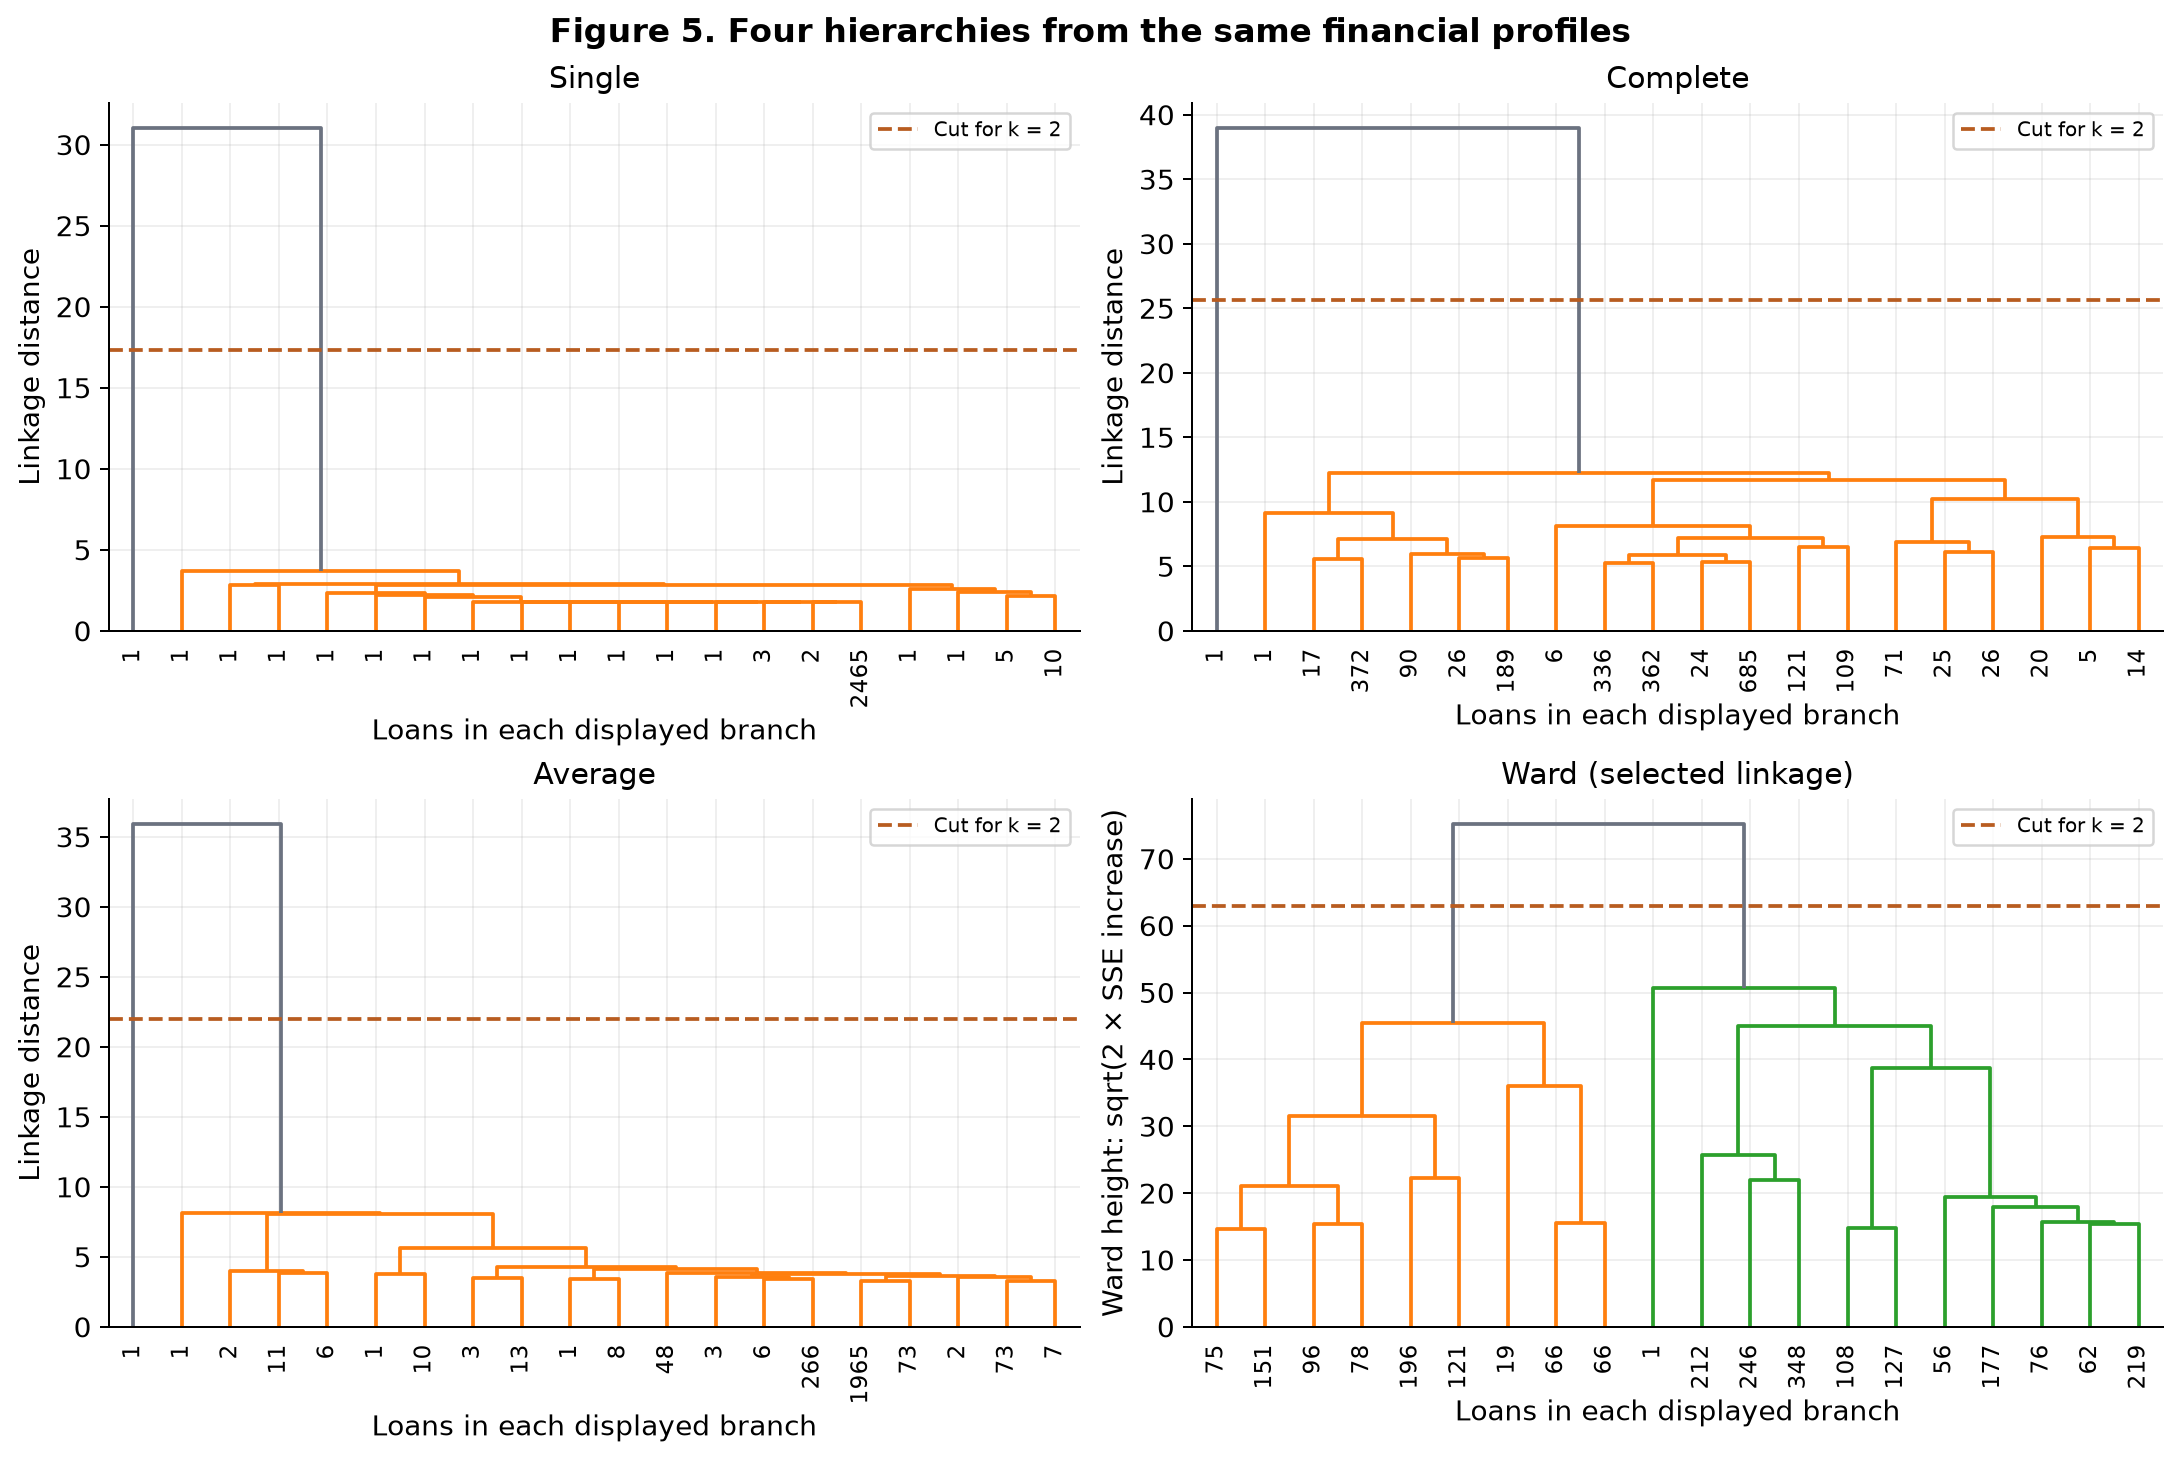

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")
for ax, method in zip(axes.flat, LINKAGES):
    tree = trees[method]
    height = cut_height(tree, hac_k)
    n = len(Z)
    def branch_count(node, tree=tree, n=n):
        return str(int(tree[node-n, 3])) if node >= n else "1"
    dendrogram(tree, truncate_mode="lastp", p=20, leaf_label_func=branch_count,
        leaf_rotation=90, leaf_font_size=9, color_threshold=height if height is not None else 0,
        above_threshold_color=GRAY, ax=ax)
    title = method.title() + (" (selected linkage)" if method == hac_method else "")
    if height is not None:
        ax.axhline(height, color=ORANGE, ls="--", label=f"Cut for k = {hac_k}")
        ax.legend(fontsize=8)
    else:
        title += "\nTied heights: exact-k cut follows merge order"
    ax.set(title=title, xlabel="Loans in each displayed branch",
        ylabel="Ward height: sqrt(2 × SSE increase)" if method == "ward" else "Linkage distance")
fig.suptitle("Figure 5. Four hierarchies from the same financial profiles", fontweight="bold")
finish(fig, "figure_5_dendrograms")

## 8. Compare the groups and describe their profiles
I include a K-means reference fitted on this exact sample, with the selected HAC group count and 20 initializations. This connects the analysis to Week 10 without reusing results from a different sample. It is not a new search for the best K-means k.

The first comparison reports coverage and silhouette. DBSCAN's score leaves noise out, while HAC and K-means cover every loan. I also score all three partitions on the same DBSCAN-assigned part of the evaluation pool. That makes the evaluated rows match, but still leaves out the loans DBSCAN rejected. A missing silhouette means the required number of distinct groups was not present.

Adjusted Rand index (ARI) compares the partitions without depending on cluster numbering. I compare DBSCAN with the others only on loans it assigned. I do not treat its scattered noise points as one coherent group. ARI measures agreement between methods, not agreement with the truth.

Figure 6 uses PCA only for a two-dimensional view. The clustering still uses all six transformed features. Figure 7 and the original-unit medians help explain the profiles. The heatmap shows group means of transformed features, not feature importance or risk scores.

Method,Clusters,Coverage,Silhouette,Evaluated loans,Silhouette on common DBSCAN-assigned pool
DBSCAN,1,0.913,NaN,731,NaN
HAC,2,1.000,0.204,800,0.181
K-means reference,2,1.000,0.208,800,0.201


Common DBSCAN-assigned evaluation pool: 731 loans


Methods,Loans compared,ARI
DBSCAN / HAC,2283,NaN
DBSCAN / K-means reference,2283,NaN
HAC / K-means reference,2500,0.617


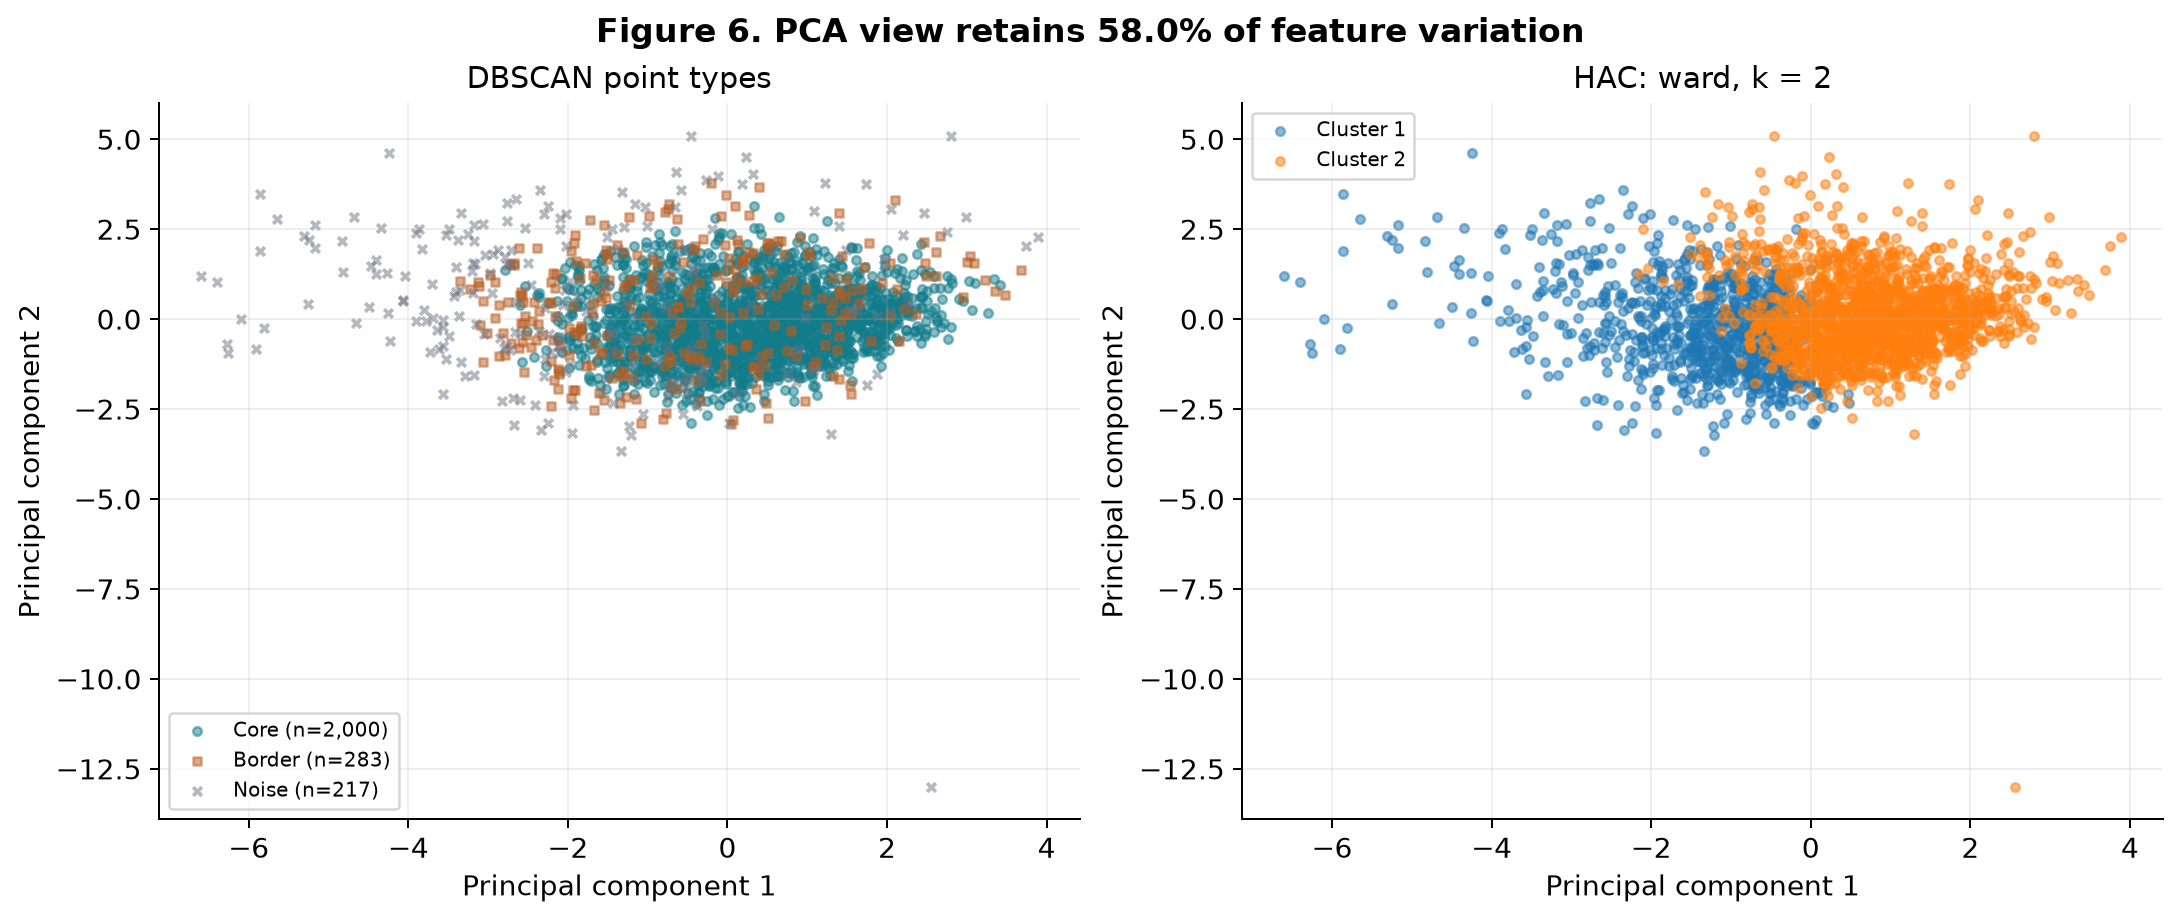

Method,Group name,Loans,loan_amnt,annual_inc,dti,fico_range_low,revol_util,revol_bal
DBSCAN,Noise,217,"6,125.0","55,000.0",13.0,720.0,16.4,"2,500.0"
DBSCAN,Cluster 1,2283,"13,000.0","65,000.0",18.4,685.0,54.2,"11,570.0"
HAC,Cluster 1,868,"7,200.0","45,000.0",16.9,695.0,32.3,"5,461.0"
HAC,Cluster 2,1632,"16,000.0","77,945.5",18.5,685.0,61.6,"15,644.5"


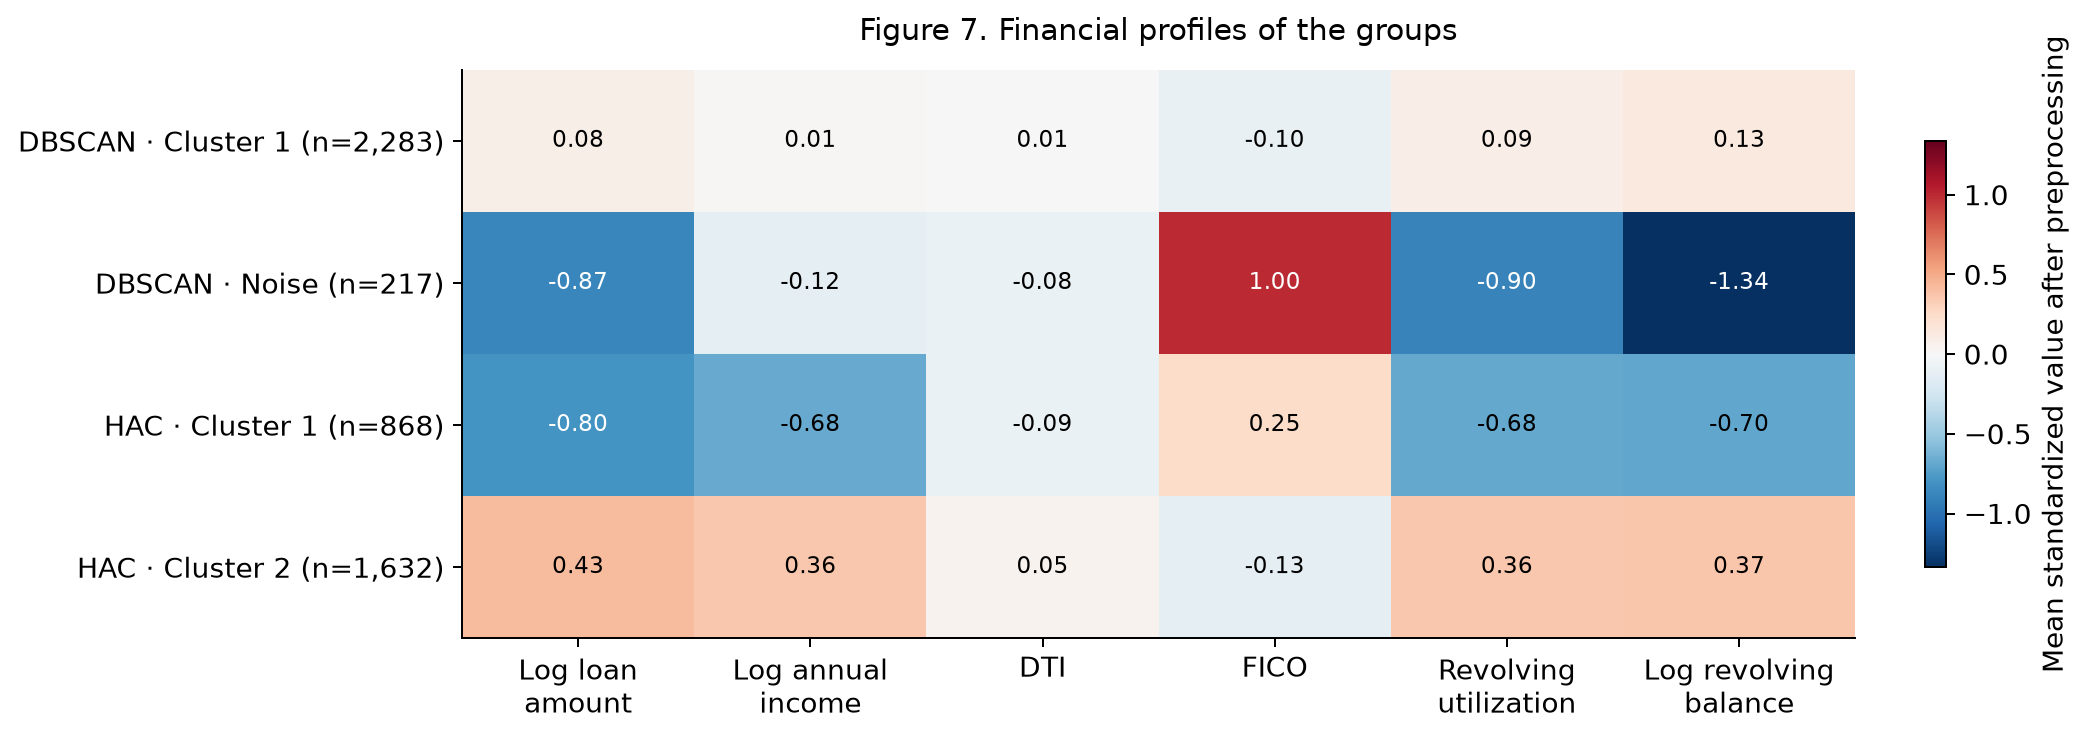

Figure 7 includes all HAC groups and up to six largest DBSCAN groups plus noise. The CSV contains every group.


In [12]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", ConvergenceWarning)
    km = KMeans(n_clusters=hac_k, n_init=20, random_state=SEED, max_iter=500, algorithm="lloyd").fit(Z)
if any(issubclass(w.category, ConvergenceWarning) for w in caught) or km.n_iter_ >= 500:
    raise RuntimeError("The K-means reference did not converge cleanly.")
partitions = {"DBSCAN": db_labels, "HAC": hac_labels, "K-means reference": km.labels_}
common_positions = eval_positions[db_labels[eval_positions] >= 0]
comparison_rows = []
for name, labels in partitions.items():
    row = {"Method": name, **partition_stats(Z, labels, eval_positions)}
    row["Silhouette on common DBSCAN-assigned pool"] = safe_silhouette(Z[common_positions], labels[common_positions])
    comparison_rows.append(row)
comparison = pd.DataFrame(comparison_rows)
show_table(comparison[["Method", "Clusters", "Coverage", "Silhouette", "Evaluated loans",
                       "Silhouette on common DBSCAN-assigned pool"]])
print(f"Common DBSCAN-assigned evaluation pool: {len(common_positions):,} loans")
comparison.to_csv(OUTPUT_DIR / "method_comparison.csv", index=False)
agreement_rows = []
for first, second in [("DBSCAN", "HAC"), ("DBSCAN", "K-means reference"), ("HAC", "K-means reference")]:
    mask = (db_labels >= 0) if first == "DBSCAN" else np.ones(len(Z), dtype=bool)
    a, b = partitions[first][mask], partitions[second][mask]
    score = adjusted_rand_score(a, b) if len(a) > 1 and len(np.unique(a)) > 1 and len(np.unique(b)) > 1 else np.nan
    agreement_rows.append({"Methods": f"{first} / {second}", "Loans compared": int(mask.sum()), "ARI": score})
agreement = pd.DataFrame(agreement_rows)
show_table(agreement)
agreement.to_csv(OUTPUT_DIR / "partition_agreement.csv", index=False)

pca = PCA(n_components=2, svd_solver="full")
coordinates = pca.fit_transform(Z)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
for kind, marker, color in [("Core", "o", TEAL), ("Border", "s", ORANGE), ("Noise", "x", GRAY)]:
    mask = db_types == kind
    if mask.any():
        axes[0].scatter(coordinates[mask, 0], coordinates[mask, 1], s=12, marker=marker,
                        alpha=.5, color=color, label=f"{kind} (n={mask.sum():,})")
for label in np.unique(hac_labels):
    mask = hac_labels == label
    axes[1].scatter(coordinates[mask, 0], coordinates[mask, 1], s=12, alpha=.5,
                    color=COLORS[label % len(COLORS)], label=group_name(label))
axes[0].set_title("DBSCAN point types")
axes[1].set_title(f"HAC: {hac_method}, k = {hac_k}")
for ax in axes:
    ax.set(xlabel="Principal component 1", ylabel="Principal component 2")
    ax.legend(fontsize=8)
fig.suptitle(f"Figure 6. PCA view retains {pca.explained_variance_ratio_.sum():.1%} of feature variation", fontweight="bold")
finish(fig, "figure_6_pca_groups")

profile_parts = []
heat_values, heat_labels = [], []
for name, labels in [("DBSCAN", db_labels), ("HAC", hac_labels)]:
    frame = X.assign(Group=labels)
    medians = frame.groupby("Group")[CLUSTER_FEATURES].median()
    medians.insert(0, "Loans", frame.groupby("Group").size())
    medians.insert(0, "Group name", [group_name(i) for i in medians.index])
    medians.insert(0, "Method", name)
    profile_parts.append(medians.reset_index())
    # Show every HAC group; for DBSCAN show up to six largest groups plus noise.
    selected_labels = sorted(i for i in medians.index if i >= 0)
    if name == "DBSCAN":
        selected_labels = medians.loc[medians.index >= 0].nlargest(6, "Loans").index.tolist()
        if -1 in medians.index:
            selected_labels += [-1]
    for label in selected_labels:
        mask = labels == label
        heat_values.append(Z[mask].mean(axis=0))
        heat_labels.append(f"{name} · {group_name(label)} (n={mask.sum():,})")
profiles = pd.concat(profile_parts, ignore_index=True)
show_table(profiles.drop(columns="Group"), 1)
profiles.to_csv(OUTPUT_DIR / "original_unit_profiles.csv", index=False)
heat_values = np.vstack(heat_values)
limit = max(1., float(np.abs(heat_values).max()))
fig, ax = plt.subplots(figsize=(11.5, max(4., .46*len(heat_labels)+1.6)), layout="constrained")
im = ax.imshow(heat_values, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
ax.set_yticks(range(len(heat_labels)), heat_labels)
ax.set_xticks(range(6), ["Log loan\namount", "Log annual\nincome", "DTI", "FICO", "Revolving\nutilization", "Log revolving\nbalance"])
ax.grid(False)
for row in range(len(heat_labels)):
    for col in range(6):
        value = heat_values[row, col]
        ax.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(value) > limit*.55 else "black")
fig.colorbar(im, ax=ax, shrink=.75, label="Mean standardized value after preprocessing")
ax.set_title("Figure 7. Financial profiles of the groups", pad=12)
finish(fig, "figure_7_profiles")
print("Figure 7 includes all HAC groups and up to six largest DBSCAN groups plus noise. The CSV contains every group.")

## 9. Check whether the groups depend on the sample
I repeat both methods on three random 80% subsets. Each time I refit the imputer and scaler, keep the selected settings fixed, and compare the new labels with the original labels for the retained loans. These overlapping subsets are a sensitivity check, not independent test sets.

For HAC, I report ARI across all retained loans. For DBSCAN, I report noise-status agreement and ARI only where both runs assign a cluster. I leave ARI missing if either partition has only one assigned group. High noise agreement alone would not show that the actual clusters are stable.

Removing observations lowers local density. Keeping eps and min_samples fixed tests that sensitivity directly; it does not isolate random sampling from density changes. Limiting the search and checking small groups reduces the chance of choosing an overly detailed partition, but it cannot prove that the groups are natural borrower types.

In [13]:
stability_rows = []
for seed in [7, 21, 99]:
    kept = np.sort(np.random.default_rng(seed).choice(len(X), int(.8*len(X)), replace=False))
    Z_sub = make_prepare().fit_transform(X.iloc[kept])
    sub_db = DBSCAN(eps=db_eps, min_samples=db_minpts, metric="euclidean", algorithm="ball_tree", n_jobs=1).fit_predict(Z_sub)
    sub_hac = cut_tree(linkage(Z_sub, method=hac_method, metric="euclidean"), n_clusters=[hac_k])[:, 0]
    original_db = db_labels[kept]
    jointly_assigned = (original_db >= 0) & (sub_db >= 0)
    a, b = original_db[jointly_assigned], sub_db[jointly_assigned]
    db_ari = adjusted_rand_score(a, b) if len(a) > 1 and len(np.unique(a)) > 1 and len(np.unique(b)) > 1 else np.nan
    stability_rows.append({"Seed": seed, "Retained loans": len(kept),
        "HAC ARI": adjusted_rand_score(hac_labels[kept], sub_hac),
        "DBSCAN noise-status agreement": float(np.mean((original_db == -1) == (sub_db == -1))),
        "DBSCAN jointly assigned loans": int(jointly_assigned.sum()),
        "DBSCAN ARI on jointly assigned loans": db_ari,
        "DBSCAN new noise share": float(np.mean(sub_db == -1)),
        "DBSCAN new cluster count": len(np.unique(sub_db[sub_db >= 0]))})
stability_results = pd.DataFrame(stability_rows)
show_table(stability_results)
stability_results.to_csv(OUTPUT_DIR / "subsample_stability.csv", index=False)

Seed,Retained loans,HAC ARI,DBSCAN noise-status agreement,DBSCAN jointly assigned loans,DBSCAN ARI on jointly assigned loans,DBSCAN new noise share,DBSCAN new cluster count
7,2000,0.304,0.988,1811,NaN,0.093,1
21,2000,0.378,0.969,1756,NaN,0.122,1
99,2000,0.497,0.963,1753,NaN,0.123,1


## 10. Look at repayment after fixing the groups
I now bring loan_status back to describe the groups. I report loan counts and observed charge-off shares for HAC and DBSCAN, including DBSCAN noise as a separate reporting category. Noise points are not assumed to resemble one another.

The error bars are approximate 95% Wilson intervals for each group's observed share. They assume independent observations and do not account for the uncertainty in clustering or the choice of features. These are descriptive results from the same loans used to form the groups, not a test of repayment prediction. I do not use the charge-off shares to revise the settings.

Method,Group name,Loans,Charged_off,Charge-off share,Lower 95%,Upper 95%
DBSCAN,Noise,217,37,0.171,0.126,0.226
DBSCAN,Cluster 1,2283,456,0.200,0.184,0.217
HAC,Cluster 1,868,161,0.185,0.161,0.213
HAC,Cluster 2,1632,332,0.203,0.185,0.224


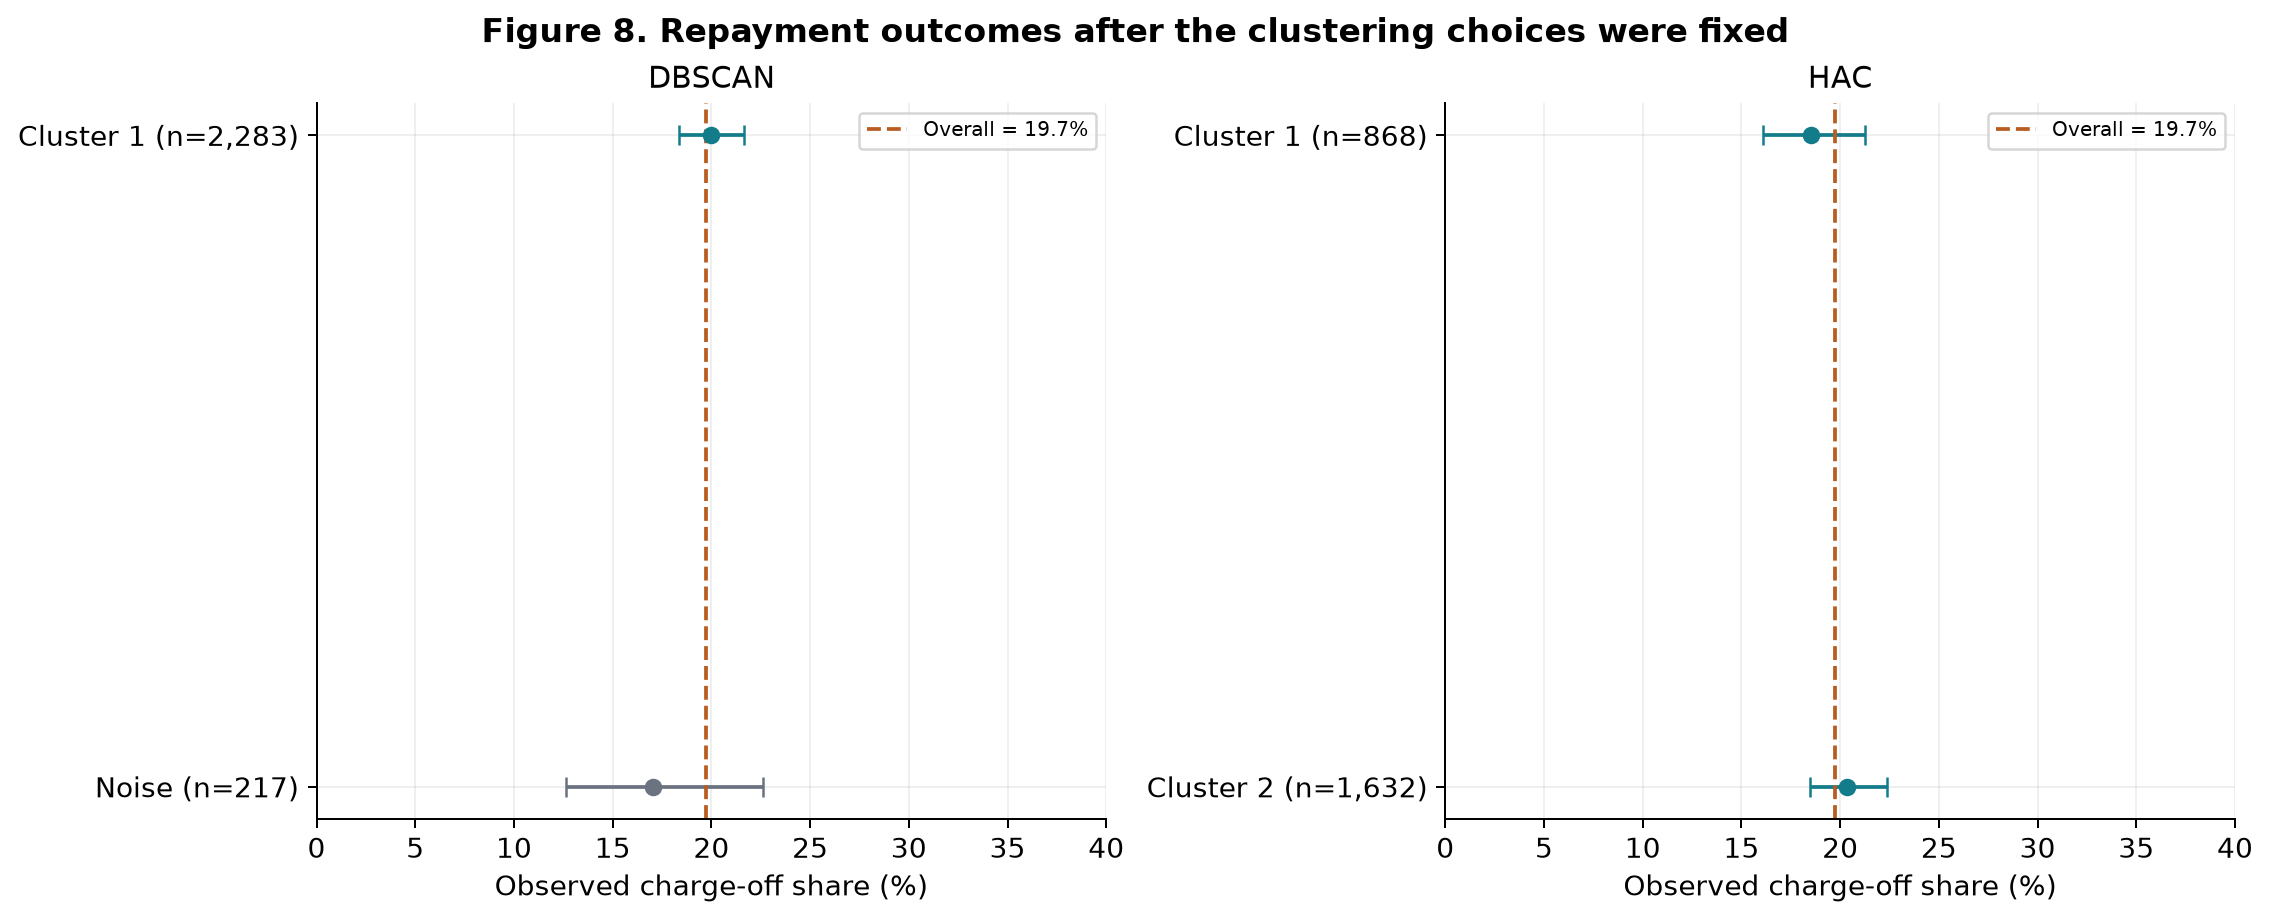

DBSCAN plot: up to six largest clusters plus noise. Full results are in observed_outcome_profiles.csv.


In [14]:
observed = study.loan_status.map({"Fully Paid": 0, "Charged Off": 1}).astype(int).to_numpy()
outcome_parts = []
for name, labels in [("DBSCAN", db_labels), ("HAC", hac_labels)]:
    table = pd.DataFrame({"Group": labels, "Charged off": observed}).groupby("Group")["Charged off"].agg(
        Loans="size", Charged_off="sum")
    n = table.Loans.to_numpy(dtype=float)
    p = table.Charged_off.to_numpy()/n
    z = 1.96
    denominator = 1+z*z/n
    center = (p+z*z/(2*n))/denominator
    half = z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/denominator
    table["Charge-off share"] = p
    table["Lower 95%"] = np.maximum(0, center-half)
    table["Upper 95%"] = np.minimum(1, center+half)
    table.insert(0, "Group name", [group_name(i) for i in table.index])
    table.insert(0, "Method", name)
    outcome_parts.append(table.reset_index())
outcome_profiles = pd.concat(outcome_parts, ignore_index=True)
show_table(outcome_profiles.drop(columns="Group"))
outcome_profiles.to_csv(OUTPUT_DIR / "observed_outcome_profiles.csv", index=False)
pd.DataFrame({"source_row": study.source_row.to_numpy(), "DBSCAN label": db_labels,
    "DBSCAN point type": db_types, "HAC label": hac_labels, "K-means reference label": km.labels_,
    "observed_charged_off": observed}).to_csv(OUTPUT_DIR / "loan_assignments.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5), layout="constrained")
for ax, name in zip(axes, ["DBSCAN", "HAC"]):
    part = outcome_profiles.loc[outcome_profiles.Method.eq(name)].copy()
    if name == "DBSCAN":
        part = pd.concat([part.loc[part.Group.ge(0)].nlargest(6, "Loans"), part.loc[part.Group.eq(-1)]])
    part = part.reset_index(drop=True)
    for row, record in part.iterrows():
        rate = record["Charge-off share"]*100
        lower, upper = record["Lower 95%"]*100, record["Upper 95%"]*100
        ax.errorbar(rate, row, xerr=[[max(0., rate-lower)], [max(0., upper-rate)]],
                    fmt="o", capsize=4, color=GRAY if record.Group == -1 else TEAL)
    ax.set_yticks(range(len(part)), [f"{r['Group name']} (n={int(r.Loans):,})" for _, r in part.iterrows()])
    ax.invert_yaxis()
    ax.axvline(observed.mean()*100, color=ORANGE, ls="--", label=f"Overall = {observed.mean():.1%}")
    ax.set(title=name, xlabel="Observed charge-off share (%)", xlim=(0, min(100, max(40, part["Upper 95%"].max()*100+5))))
    ax.legend(fontsize=8, loc="best")
fig.suptitle("Figure 8. Repayment outcomes after the clustering choices were fixed", fontweight="bold")
finish(fig, "figure_8_observed_outcomes")
print("DBSCAN plot: up to six largest clusters plus noise. Full results are in observed_outcome_profiles.csv.")

## 11. What I learned, limits, and next steps
I wanted to see whether another clustering method would give me borrower groups that were easier to explain. DBSCAN did not find several groups that met the rules I set, and the HAC assignments changed when I changed the sample. Those are useful results for my project because they show where I need to be careful about treating a grouping as a dependable borrower category.

## What the results showed me
The feature ranges gave me a reason to scale before clustering. In the original units, annual income accounted for 83.0% of squared distance across the sampled loan pairs. After logging the dollar features and standardizing, the largest absolute standardized value was still 35.4. Scaling changed the units, but extreme observations remained. The strongest linear correlation among the transformed features was −0.488 between FICO and revolving utilization, so the inputs were not completely unrelated either.

DBSCAN did not produce a grouping that passed all of my screens. The reference run used eps = 1.166 and MinPts = 12. It put 2,283 of the 2,500 loans into one cluster: 2,000 core points and 283 border points. The remaining 217 loans were noise, giving 91.3% coverage. With only one assigned cluster, silhouette was undefined. I would not describe this as finding several distinct borrower groups.

The noise share ranged from 1.2% to 32.3% across the settings I tested. That shows how much the density rule changed which loans were left out. In the reference run, the noise loans had a median income of $55,000 and median DTI of 13.0. Those figures describe the excluded loans, but they do not mean the noise points belong together or are more likely to charge off.

For HAC, Ward linkage with two groups was the only cut that passed all of the screens. Its silhouette was 0.204, compared with 0.208 for the two-group K-means reference fitted on the same loans and scored on the same evaluation pool. Those scores are close and do not show strong separation. I would not use the small difference to claim that either method predicts repayment better. Silhouette measures the grouping under the chosen distance, not prediction accuracy.

The largest HAC group, Cluster 2, contained 1,632 loans. Its median loan amount was $16,000, annual income was $77,946, DTI was 18.5, and FICO was 685. These summaries help me describe the group. The PCA plot is also useful for seeing the assignments, but its two components retain only 58.0% of the transformed feature variation. I cannot use that picture alone to judge separation in all six features.

The sample checks gave me another reason to be cautious. When I refitted HAC on three 80% subsets, ARI ranged from 0.304 to 0.497. The assignments changed enough that I would not treat them as fixed borrower types. For DBSCAN, the agreement about which loans were noise ranged from 96.2% to 98.8%. The assigned-cluster ARIs were undefined because the comparisons did not include at least two assigned clusters in each partition. High agreement about noise does not establish that several useful groups were stable.

After fixing the clusters, I compared their observed charge-off shares. HAC Cluster 2 had 20.3% charge-offs among 1,632 loans, while Cluster 1 had 18.5% among 868 loans. That is a 1.8 percentage-point difference. I would read it alongside the group sizes and confidence intervals. These are the same loans used to form the clusters, so the difference is descriptive evidence, not a test of future repayment prediction.
Limits and next steps
For my capstone, the useful result is seeing how much the borrower groups depend on preprocessing, the linkage rule, and the sample. The failed DBSCAN screens do not mean DBSCAN can never work on lending data. They mean the settings and six features I tested did not produce the kind of grouping I was looking for.

This analysis uses 2,500 historical accepted loans with resolved outcomes, a limited parameter search, and three overlapping sample checks. Those checks are not independent tests on new borrowers. Removing loans also changes local density, which matters for DBSCAN when the radius and minimum count stay fixed.

I would next check whether the profiles and outcome differences appear in loans issued later, and whether changes to the feature set produce groups I can explain more consistently. I would keep repayment outcomes out of those clustering choices. Before claiming that clustering helps identify charge-offs, I would need a separate prediction comparison using loans held out from model selection. The results here do not establish that improvement.

### References

Scikit-learn developers. (n.d.-a). Clustering. scikit-learn. https://scikit-learn.org/stable/modules/clustering.html

Scikit-learn developers. (n.d.-b). DBSCAN. scikit-learn. https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html

Scikit-learn developers. (n.d.-c). Silhouette_score. scikit-learn. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html

SciPy community. (n.d.-a). Cut_tree. SciPy. https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.cut_tree.html

SciPy community. (n.d.-b). Dendrogram. SciPy. https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.dendrogram.html

SciPy community. (n.d.-c). Linkage. SciPy. https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html

Wordsforthewise. (n.d.). All Lending Club loan data (Version 3) [Data set]. Kaggle. https://www.kaggle.com/datasets/wordsforthewise/lending-club